# ¿Quién vota hoy a la derecha porteña?

**Nivel socioeconómico, abstención y la alianza LLA-PRO (2023–2025)**

Este notebook reconstruye y analiza resultados electorales de la Ciudad Autónoma de Buenos Aires a nivel de circuito electoral (167 circuitos), integra indicadores del Censo 2022 y genera tablas para visualización.

## Índice
1. Configuración
2. Elecciones 2023 y octubre 2025 (DINE)
3. Reconstrucción de mayo 2025 (scraping del Tribunal Electoral)
4. Censo 2022 por circuito
5. Análisis
6. Datos para gráficos
7. Resumen de validaciones

## Entradas
- Resultados y locales de votación DINE 2023 y octubre 2025.
- Resultados por establecimiento y mesa del Tribunal Electoral de CABA para mayo 2025.
- Censo 2022 por radio censal y geometrías de radios de Source Cooperative.
- GeoJSON de circuitos electorales de BA Data.

Las fuentes se descargan o se colocan en `data/raw/`. Los archivos intermedios se guardan en `data/processed/`.

## Salidas
- Tablas intermedias por mesa, escuela, circuito y elección en `data/processed/`.
- CSV y GeoJSON para Datawrapper en `output/datawrapper/`.

**Comparabilidad electoral:** la comparación principal es diputados nacionales 2023 vs. legisladores porteños de mayo 2025 (solo argentinos) vs. diputados nacionales de octubre 2025. Legisladores porteños 2023 se conserva únicamente como control de robustez.

## 1. Configuración

Se centralizan dependencias, rutas, constantes geográficas y controles de descarga para que el notebook pueda ejecutarse desde un repositorio local.

In [3]:
#!pip install -q geopandas statsmodels rapidfuzz beautifulsoup4 pyarrow tqdm lxml

In [4]:
# Imports
import io
import json
import os
import re
import time
import unicodedata
import zipfile
from pathlib import Path
from urllib.parse import urljoin

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import statsmodels.formula.api as smf
from bs4 import BeautifulSoup
from rapidfuzz import process, fuzz
from tqdm.auto import tqdm

# Rutas del proyecto
DATA_RAW = "data/raw"
DATA_PROCESSED = "data/processed"
OUTPUT = "output"
for carpeta in (DATA_RAW, DATA_PROCESSED, OUTPUT):
    os.makedirs(carpeta, exist_ok=True)

# Descargas desactivadas por defecto: se utilizan los archivos locales ya descargados.
DESCARGAR = False

# Montaje opcional de Google Drive (solo para trabajar desde Colab):
# from google.colab import drive
# drive.mount('/content/drive')

# Google Drive (Colab)
from google.colab import drive
drive.mount('/content/drive')

# Directorio raíz del proyecto
PROJECT_DIR = Path('/content/drive/MyDrive/Proyecto_Electoral_CABA')
os.chdir(PROJECT_DIR)

# Rutas relativas
DATA_RAW = "data/raw"
DATA_PROCESSED = "data/processed"
OUTPUT = "output"

for carpeta in (DATA_RAW, DATA_PROCESSED, OUTPUT):
    os.makedirs(carpeta, exist_ok=True)

# Fuentes
URL_2023 = 'https://www.argentina.gob.ar/sites/default/files/2023_generales_1.zip'
URL_2025 = 'http://datos.mininterior.gob.ar/dataset/947e871a-650e-4b63-8939-ecb29acb717c/resource/a24110fb-bfcf-47a6-8aa7-2e53dab9caf5/download/elecciones_legislativas_2025.zip'
BASE = 'https://resultados.electoralcaba.gob.ar'
BASE_CENSO = 'https://data.source.coop/nlebovits/censo-argentino/2022'
URL_CIRC = 'https://cdn.buenosaires.gob.ar/datosabiertos/datasets/subsecretaria-justicia/circuitos-electorales/circuitos-electorales.geojson'
HEADERS = {'User-Agent': 'Mozilla/5.0 (proyecto personal de análisis electoral)'}

# Proyección Gauss-Krüger Buenos Aires utilizada para las geometrías de CABA.
GKBA = ('+proj=tmerc +lat_0=-34.629269 +lon_0=-58.4633 +k=0.9999980 '
        '+x_0=100000 +y_0=100000 +ellps=intl +towgs84=-148,136,90,0,0,0,0 +units=m +no_defs')
UMBRAL = 8000  # debajo: mesas de argentinos; desde 8000: bloque de extranjeros
COLS_NUMERICAS = ['distrito_id', 'seccion_id', 'mesa_id', 'mesa_electores',
                  'cargo_id', 'agrupacion_id', 'votos_cantidad', 'localvotacion_codigo']

# Toda petición HTTP pasa por este wrapper: pausa mínima de 0,5 segundos.
def request_get(url, **kwargs):
    if not DESCARGAR:
        raise RuntimeError('DESCARGAR=False: no se permiten peticiones HTTP. Activá DESCARGAR solo para actualizar las fuentes.')
    try:
        return requests.get(url, **kwargs)
    finally:
        time.sleep(0.5)

# Lectura local con mensaje explícito cuando falta un archivo necesario.
def exigir_archivo(ruta):
    if not os.path.exists(ruta):
        raise FileNotFoundError(
            f"No se encontró {ruta}. Colocá el archivo en esa ruta o ejecutá la descarga "
            "correspondiente con DESCARGAR = True."
        )
    return ruta

pd.set_option('display.max_rows', 100)

Mounted at /content/drive


## 2. Elecciones 2023 y octubre 2025 (DINE)

Se filtran los registros de CABA, se normalizan los identificadores de circuito y se conservan los controles de cobertura por comuna, mesas y electores.

In [5]:
def bajar_zip(url):
    if not DESCARGAR:
        raise RuntimeError('bajar_zip requiere DESCARGAR=True.')
    respuesta = request_get(url, timeout=120)
    return zipfile.ZipFile(io.BytesIO(respuesta.content))

def filtrar_caba(z, archivo):
    partes = []
    for chunk in pd.read_csv(z.open(archivo), chunksize=500_000, dtype=str):
        partes.append(chunk[pd.to_numeric(chunk['distrito_id'], errors='coerce') == 1])
    df = pd.concat(partes, ignore_index=True)
    for columna in COLS_NUMERICAS:
        if columna in df.columns:
            df[columna] = pd.to_numeric(df[columna], errors='coerce')
    return df

ARCH_R23 = f'{DATA_PROCESSED}/caba_2023_generales.parquet'
ARCH_R25 = f'{DATA_PROCESSED}/caba_2025_octubre.parquet'
ARCH_LOCALES25 = f'{DATA_PROCESSED}/caba_2025_locales.parquet'

if DESCARGAR:
    z23 = bajar_zip(URL_2023)
    r23 = filtrar_caba(z23, '2023_Generales/ResultadoElectorales_2023_Generales.csv')
    r23.to_parquet(ARCH_R23, index=False)
    del z23

    z25 = bajar_zip(URL_2025)
    r25 = filtrar_caba(z25, 'resultados2025.csv')
    locales25 = filtrar_caba(z25, 'localesDeVotacionyMesas.csv')
    r25.to_parquet(ARCH_R25, index=False)
    locales25.to_parquet(ARCH_LOCALES25, index=False)
    del z25
else:
    r23 = pd.read_parquet(exigir_archivo(ARCH_R23))
    r25 = pd.read_parquet(exigir_archivo(ARCH_R25))
    locales25 = pd.read_parquet(exigir_archivo(ARCH_LOCALES25))

for df in (r23, r25):
    df['circuito_id'] = df['circuito_id'].astype(str).str.zfill(5)

print('DINE 2023:', r23.shape)
print('DINE octubre 2025:', r25.shape)
print('Locales octubre 2025:', locales25.shape)

DINE 2023: (515822, 25)
DINE octubre 2025: (305928, 26)
Locales octubre 2025: (7284, 17)


## 2. ¿2023 y 2025 están completos y son comparables?

Por cada comuna (`seccion_id`) contamos circuitos, mesas y electores. Si ambos años tienen las 15 comunas y cifras parecidas, los datos están completos.

Usamos `seccion_id` y no el nombre porque se escribe distinto en cada año (*Comuna 01* vs. *COMUNA 1*).

In [6]:
def resumen(df, anio):
    mesas = df.drop_duplicates(['seccion_id', 'mesa_id'])
    return (mesas.groupby('seccion_id')
                 .agg(circuitos=('circuito_id', 'nunique'),
                      mesas=('mesa_id', 'nunique'),
                      electores=('mesa_electores', 'sum'))
                 .add_prefix(f'{anio}_'))

comp = resumen(r23, '2023').join(resumen(r25, '2025'), how='outer')
comp['dif_mesas'] = comp['2025_mesas'] - comp['2023_mesas']
comp.loc['TOTAL'] = comp.sum()
comp

,2023_circuitos,2023_mesas,2023_electores,2025_circuitos,2025_mesas,2025_electores,dif_mesas
seccion_id,,,,,,,
1,19,711,242790,19,516,177622,-195
2,10,470,161135,10,393,135518,-77
3,13,586,201640,13,448,154041,-138
4,15,658,225193,15,524,180893,-134
5,10,523,179493,10,438,151896,-85
6,7,512,176590,7,456,158467,-56
7,12,644,221861,12,504,174054,-140
8,4,574,199324,4,423,147454,-151
9,11,508,174918,11,425,146940,-83


In [7]:
# 1. ¿Cómo vienen escritos los circuitos de la Comuna 1 en cada año?
print('2023:', sorted(r23[r23['seccion_id'] == 1]['circuito_id'].unique()))
print('2025:', sorted(r25[r25['seccion_id'] == 1]['circuito_id'].unique()))

# 2. ¿Qué tipos de mesa y de padrón hay en 2023?
mesas23 = r23.drop_duplicates(['seccion_id', 'circuito_id', 'mesa_id'])
print(mesas23.groupby(['padron_tipo', 'mesa_tipo'])['mesa_electores'].agg(['count', 'sum']))

# 3. ¿Hay mesas que aparecen en más de un circuito?
rep = mesas23.groupby(['seccion_id', 'mesa_id'])['circuito_id'].nunique()
print('Mesas en más de un circuito:', (rep > 1).sum())

2023: ['00001', '00002', '00003', '00004', '00005', '00006', '00007', '00008', '00009', '00010', '00011', '00012', '00013', '00014', '00015', '00016', '00017', '00018', '00019']
2025: ['00001', '00002', '00003', '00004', '00005', '00006', '00007', '00008', '00009', '00010', '00011', '00012', '00013', '00014', '00015', '00016', '00017', '00018', '00019']
                         count      sum
padron_tipo mesa_tipo                  
NORMAL      EXTRANJEROS   1444   486538
            NATIVOS       7326  2526676
Mesas en más de un circuito: 0


In [8]:
# 1. Unificar el formato: todo a 5 dígitos ('1' -> '00001')
for df in (r23, r25):
    df['circuito_id'] = df['circuito_id'].str.zfill(5)

# 2. ¿Qué cargos vota cada tipo de mesa en 2023?
print(r23.groupby(['mesa_tipo', 'cargo_nombre']).size())

# 3. Repetir la comparación, solo nativos
def resumen(df, anio):
    mesas = df.drop_duplicates(['seccion_id', 'mesa_id'])
    return (mesas.groupby('seccion_id')
                 .agg(circuitos=('circuito_id', 'nunique'),
                      mesas=('mesa_id', 'nunique'),
                      electores=('mesa_electores', 'sum'))
                 .add_prefix(f'{anio}_'))

n23 = r23[r23['mesa_tipo'] == 'NATIVOS']
n25 = r25[r25['mesa_tipo'] == 'NATIVOS']

comp = resumen(n23, '2023').join(resumen(n25, '2025'), how='outer')
comp['dif_mesas'] = comp['2025_mesas'] - comp['2023_mesas']
comp.loc['TOTAL'] = comp.sum()
comp

mesa_tipo    cargo_nombre                      
EXTRANJEROS  DIPUTADOS/AS DE LA CIUDAD AUTONOMA    12996
             JEFE/A DE GOBIERNO                    12996
             MIEMBROS DE JUNTA COMUNAL             13136
NATIVOS      DIPUTADO NACIONAL                     65934
             DIPUTADOS/AS DE LA CIUDAD AUTONOMA    65934
             JEFE/A DE GOBIERNO                    65934
             MIEMBROS DE JUNTA COMUNAL             66438
             PARLAMENTO MERCOSUR NACIONAL          73260
             PARLAMENTO MERCOSUR REGIONAL          65934
             PRESIDENTE Y VICE                     73260
dtype: int64


,2023_circuitos,2023_mesas,2023_electores,2025_circuitos,2025_mesas,2025_electores,dif_mesas
seccion_id,,,,,,,
1,19,515,176202,19,516,177622,1
2,10,400,137779,10,393,135518,-7
3,13,450,155066,13,448,154041,-2
4,15,526,180576,15,524,180893,-2
5,10,446,153414,10,438,151896,-8
6,7,459,159176,7,456,158467,-3
7,12,504,174167,12,504,174054,0
8,4,422,146694,4,423,147454,1
9,11,427,147324,11,425,146940,-2


In [9]:
# Persistencia de las bases DINE ya filtradas y normalizadas.
r23.to_parquet(ARCH_R23, index=False)
r25.to_parquet(ARCH_R25, index=False)
locales25.to_parquet(ARCH_LOCALES25, index=False)
print('Bases DINE guardadas en', DATA_PROCESSED)

Bases DINE guardadas en data/processed


### Persistencia de la sección 2

Las bases DINE filtradas para CABA y el catálogo de locales quedan disponibles para las secciones siguientes.

In [10]:
r23.to_parquet(ARCH_R23, index=False)
r25.to_parquet(ARCH_R25, index=False)
locales25.to_parquet(ARCH_LOCALES25, index=False)

## 3. Reconstrucción de mayo 2025 (scraping del Tribunal Electoral)

La reconstrucción conserva las reglas originales de correspondencia entre establecimientos, mesas y circuitos. Las descargas solo se ejecutan cuando `DESCARGAR = True`; con el valor predeterminado se leen los archivos guardados en `data/raw/`.

### 3.1. Relevamiento de establecimientos y correspondencia con DINE

Se compara el listado de establecimientos del Tribunal Electoral con los locales de octubre de DINE. Esta etapa identifica coincidencias exactas, nombres repetidos y casos que requieren fuzzy matching.

In [11]:
ARCH_TRIBUNAL = f'{DATA_RAW}/tribunal_mayo2025_establecimientos.csv'
if DESCARGAR:
    filas = []
    for comuna_id in range(1, 16):
        resp = request_get(f'{BASE}/seccion/?{comuna_id}', headers=HEADERS, timeout=30)
        soup = BeautifulSoup(resp.text, 'html.parser')
        for a in soup.find_all('a', href=True):
            if 'establecimientos' in a['href']:
                filas.append({'seccion_id': comuna_id,
                              'establecimiento': a.get_text(strip=True),
                              'url': urljoin(f'{BASE}/seccion/', a['href'])})
    tribunal = pd.DataFrame(filas).drop_duplicates()
    tribunal.to_csv(ARCH_TRIBUNAL, index=False)
else:
    tribunal = pd.read_csv(exigir_archivo(ARCH_TRIBUNAL))

print('Establecimientos del Tribunal:', len(tribunal))
conteo_establecimientos = pd.DataFrame({
    'octubre_dine': locales25.groupby('seccion_id')['localvotacion_codigo'].nunique(),
    'mayo_tribunal': tribunal.groupby('seccion_id')['establecimiento'].nunique(),
})
conteo_establecimientos['diferencia'] = (conteo_establecimientos['mayo_tribunal'] -
                                          conteo_establecimientos['octubre_dine'])
conteo_establecimientos.loc['TOTAL'] = conteo_establecimientos.sum()
display(conteo_establecimientos)

# Circuito de cada mesa de octubre y correspondencia con el establecimiento.
mesa_circ25 = r25.drop_duplicates(['seccion_id', 'mesa_id'])[['seccion_id', 'mesa_id', 'circuito_id']]
loc_circ = locales25.merge(mesa_circ25, on=['seccion_id', 'mesa_id'], how='left')
circ_por_escuela = loc_circ.groupby('localvotacion_codigo')['circuito_id'].nunique()
print('Escuelas según cantidad de circuitos:')
print(circ_por_escuela.value_counts())
print('Mesas sin circuito asignado:', loc_circ['circuito_id'].isna().sum())

# Normalización de nombres para reducir diferencias ortográficas y de formato.
def normalizar(texto):
    texto = re.sub(r'N\s*\.?\s*[º°]', 'N ', str(texto))
    texto = unicodedata.normalize('NFKD', texto)
    texto = texto.encode('ascii', 'ignore').decode()
    texto = texto.upper()
    texto = re.sub(r'[^A-Z0-9 ]', ' ', texto)
    return re.sub(r'\s+', ' ', texto).strip()

escuela_circ = (loc_circ.drop_duplicates('localvotacion_codigo')
                [['seccion_id', 'localvotacion_codigo', 'localvotacion_nombre',
                  'localvotacion_direccion', 'circuito_id']].copy())
escuela_circ.to_csv(f'{DATA_PROCESSED}/escuela_circuito_oct2025.csv', index=False)
tribunal = tribunal[tribunal['establecimiento'].str.strip().str.lower() != 'prueba'].copy()
escuela_circ['nombre_norm'] = escuela_circ['localvotacion_nombre'].apply(normalizar)
tribunal['nombre_norm'] = tribunal['establecimiento'].apply(normalizar)
dup = escuela_circ.duplicated(['seccion_id', 'nombre_norm'], keep=False)
print('Escuelas DINE con nombre repetido en su comuna:', dup.sum())
display(escuela_circ[dup].sort_values(['seccion_id', 'nombre_norm'])
        [['seccion_id', 'localvotacion_nombre', 'localvotacion_direccion', 'circuito_id']])

circ_unico = (escuela_circ.groupby(['seccion_id', 'nombre_norm'])['circuito_id']
              .agg(lambda s: s.iloc[0] if s.nunique() == 1 else 'AMBIGUO')
              .reset_index())
match = tribunal.merge(circ_unico, on=['seccion_id', 'nombre_norm'], how='left')
print('Filas:', len(match), '| Ambiguas:', (match['circuito_id'] == 'AMBIGUO').sum(),
      '| Sin match:', match['circuito_id'].isna().sum())

filas_fuzzy = []
for _, row in match[match['circuito_id'].isna()].iterrows():
    candidatos = escuela_circ[escuela_circ['seccion_id'] == row['seccion_id']]
    nombre, score, idx = process.extractOne(row['nombre_norm'], candidatos['nombre_norm'],
                                            scorer=fuzz.token_set_ratio)
    filas_fuzzy.append({'seccion_id': row['seccion_id'], 'mayo': row['establecimiento'],
                        'octubre_sugerido': candidatos.loc[idx, 'localvotacion_nombre'],
                        'circuito_sugerido': candidatos.loc[idx, 'circuito_id'],
                        'score': round(score)})
fuzzy = pd.DataFrame(filas_fuzzy).sort_values('score')
display(fuzzy)

# Se conservan los rechazos manuales del fuzzy matching original.
rechazadas = [39, 48, 34, 5, 10, 35, 42]
aceptadas = fuzzy.drop(index=rechazadas)
sug = {(r.seccion_id, r.mayo): r.circuito_sugerido for r in aceptadas.itertuples()}
match['metodo'] = 'exacto'
match.loc[match['circuito_id'] == 'AMBIGUO', 'metodo'] = 'ambiguo'
match.loc[match['circuito_id'].isna(), 'metodo'] = 'pendiente'
for i, r in match[match['metodo'] == 'pendiente'].iterrows():
    clave = (r['seccion_id'], r['establecimiento'])
    if clave in sug:
        match.at[i, 'circuito_id'] = sug[clave]
        match.at[i, 'metodo'] = 'fuzzy'
match['circuito_id'] = match['circuito_id'].astype('string')
match.to_csv(f'{DATA_PROCESSED}/escuelas_mayo2025_circuito.csv', index=False)
print(match['metodo'].value_counts())
display(match[match['metodo'].isin(['ambiguo', 'pendiente'])]
        [['seccion_id', 'establecimiento', 'metodo']])

Establecimientos del Tribunal: 1128


,octubre_dine,mayo_tribunal,diferencia
seccion_id,,,
1,86,86,0
2,50,52,2
3,76,75,-1
4,93,92,-1
5,56,57,1
6,64,63,-1
7,75,76,1
8,64,66,2
9,80,82,2


Escuelas según cantidad de circuitos:
circuito_id
1    1117
Name: count, dtype: int64
Mesas sin circuito asignado: 0
Escuelas DINE con nombre repetido en su comuna: 15


,seccion_id,localvotacion_nombre,localvotacion_direccion,circuito_id
10,1,UBA FACULTAD DE CS. SOCIALES,SAN JOSE 1064,00017
11,1,UBA FACULTAD DE CS. SOCIALES,SANTIAGO DEL ESTERO 1029,00017
961,3,COLEGIO LA SALLE,RIOBAMBA 696,00031
1078,3,COLEGIO LA SALLE,TUCUMAN 1901,00032
940,3,UBA FAC. DE CS. ECONOMICAS,AV. CORDOBA 2150,00031
987,3,UBA FAC. DE CS. ECONOMICAS,J. E. URIBURU 781,00031
920,3,UBA FACULTAD DE PSICOLOGIA,AV. INDEPENDENCIA 3065,00036
1000,3,UBA FACULTAD DE PSICOLOGIA,HIPOLITO YRIGOYEN 3242,00035
1435,4,INST. SAN VICENTE DE PAUL,24 DE NOVIEMBRE 1665,00044
1452,4,INST. SAN VICENTE DE PAUL,ALBERTO EINSTEIN 599,00055


Filas: 1113 | Ambiguas: 4 | Sin match: 63


,seccion_id,mayo,octubre_sugerido,circuito_sugerido,score
39,10,La Fábrica deportiva,COLEGIO NTRA. SRA. DE LA PAZ,00112,48
48,14,C.E.A.E.S. Espíritu Santo,COLEGIO SANTA TERESA DE JESUS PRIMARIO,00152,50
34,8,Inst. Parroquial Mario F. Alsina,INST. SAGRADA FAMILIA,00088,56
5,2,Esc. Infantil Nº7 Palacio Pizzurno,ESC. Nº21 ANGEL GALLARDO,00021,57
43,11,Club Gim. y Esg. de Vélez Sársfield,CLUB GEVS,00113,62
10,3,"Esc. Nº9 ""Dr. Luis R. Mc. Kay""",ESC. Nº15 LUIS CHINETTI,00040,62
7,3,Esc. Cangallo Schule,ESCUELA CANGALLO,00034,80
29,6,Inst. SUMMA,INSTITUTO SUMMA,00069,80
27,6,Inst. Orsino,INSTITUTO ORSINO,00073,81
35,9,Club Brisas del Sud,CLUB AMERICA DEL SUD,00092,82


metodo
exacto       1046
fuzzy          56
pendiente       7
ambiguo         4
Name: count, dtype: int64


,seccion_id,establecimiento,metodo
98,2,Esc. Infantil Nº7 Palacio Pizzurno,pendiente
142,3,Colegio La Salle,ambiguo
184,3,"Esc. Nº9 ""Dr. Luis R. Mc. Kay""",pendiente
203,3,UBA - Facultad de Psicología,ambiguo
205,3,UBA - Facultad de Psicología,ambiguo
293,4,Inst. San Vicente de Paul,ambiguo
551,8,Inst. Parroquial Mario F. Alsina,pendiente
571,9,Club Brisas del Sud,pendiente
710,10,La Fábrica deportiva,pendiente
714,11,Club G. y E. de Villa del Parque,pendiente


### 3.2. Descarga de resultados por establecimiento

La función de lectura obtiene votos por agrupación y detalle de votos. El archivo permite retomar descargas parciales; con `DESCARGAR = False` se reutilizan los CSV existentes.

In [12]:
from tqdm.auto import tqdm

ARCH_VOTOS = f'{DATA_RAW}/mayo2025_votos_escuela.csv'
ARCH_MESAS = f'{DATA_RAW}/mayo2025_mesas_escuela.csv'
ARCH_VOTOS_FINAL = f'{DATA_RAW}/mayo2025_votos_escuela_final.csv'
ARCH_COMP = f'{DATA_RAW}/mayo2025_votos_mesas_compartidas.csv'
ARCH_REPARTIDAS = f'{DATA_RAW}/mayo2025_votos_mesas_repartidas.csv'
ARCH_EXT = f'{DATA_RAW}/mayo2025_votos_mesas_extranjeros.csv'


def leer_escuela(url):
    if not DESCARGAR:
        raise RuntimeError('leer_escuela requiere DESCARGAR=True.')
    html = request_get(url, headers=HEADERS, timeout=15).text
    tablas = pd.read_html(io.StringIO(html), thousands='.', decimal=',')
    agrup = tablas[1][tablas[1].iloc[:, 0].notna()]
    votos = pd.DataFrame({'agrupacion_id': agrup.iloc[:, 0].astype(int),
                          'agrupacion': agrup['AGRUPACIÓN'],
                          'votos': agrup['CANTIDAD DE VOTOS']})
    detalle = pd.DataFrame({'agrupacion_id': pd.NA,
                            'agrupacion': tablas[0]['DETALLE'],
                            'votos': tablas[0]['CANTIDAD']})
    soup = BeautifulSoup(html, 'html.parser')
    mesas = [a['href'].split('?')[1] for a in soup.find_all('a', href=True) if 'mesa' in a['href']]
    return pd.concat([votos, detalle], ignore_index=True), mesas


def guardar_csv_incremental(df, archivo):
    df.to_csv(archivo, mode='a', header=not os.path.exists(archivo), index=False)

if DESCARGAR:
    hechas = set(pd.read_csv(ARCH_VOTOS)['url']) if os.path.exists(ARCH_VOTOS) else set()
    pendientes = match[~match['url'].isin(hechas)]
    print('Escuelas pendientes:', len(pendientes))
    buf_v, buf_m, errores = [], [], []
    for r in tqdm(pendientes.itertuples(), total=len(pendientes)):
        try:
            v, m = leer_escuela(r.url)
            v['url'], v['seccion_id'], v['establecimiento'] = r.url, r.seccion_id, r.establecimiento
            buf_v.append(v)
            buf_m += [{'url': r.url, 'seccion_id': r.seccion_id, 'mesa_id': int(x)} for x in m]
        except Exception as e:
            errores.append((r.establecimiento, type(e).__name__))
        if len(buf_v) >= 50:
            guardar_csv_incremental(pd.concat(buf_v), ARCH_VOTOS)
            guardar_csv_incremental(pd.DataFrame(buf_m), ARCH_MESAS)
            buf_v, buf_m = [], []
    if buf_v:
        guardar_csv_incremental(pd.concat(buf_v), ARCH_VOTOS)
        guardar_csv_incremental(pd.DataFrame(buf_m), ARCH_MESAS)
    print('Errores de descarga:', len(errores))

votos_m = pd.read_csv(exigir_archivo(ARCH_VOTOS))
mesas_m = pd.read_csv(exigir_archivo(ARCH_MESAS))
print('Escuelas con datos:', votos_m['url'].nunique(), 'de', len(match))
print('Filas duplicadas:', votos_m.duplicated().sum())
print('Mesas encontradas:', len(mesas_m))

ARCH_OFICIALES_COMUNA = f'{DATA_RAW}/mayo2025_totales_oficiales_comuna.json'

# Los totales oficiales se obtienen de las páginas por comuna del Tribunal Electoral.
# Si DESCARGAR=True se consultan las 15 comunas y se conserva una copia local.
# Si DESCARGAR=False se utiliza el JSON existente; si falta, esta validación se omite.
if DESCARGAR:
    oficial = {}
    for comuna_id in range(1, 16):
        url_comuna = f'{BASE}/seccion/?{comuna_id}'
        html = request_get(url_comuna, headers=HEADERS, timeout=15).text
        tabla = pd.read_html(io.StringIO(html), thousands='.', decimal=',')[0]
        total = tabla.loc[tabla['DETALLE'] == 'VOTOS TOTALES', 'CANTIDAD'].iloc[0]
        oficial[comuna_id] = int(total)

    with open(ARCH_OFICIALES_COMUNA, 'w', encoding='utf-8') as archivo:
        json.dump(oficial, archivo, ensure_ascii=False, indent=2)
    print(f'Totales oficiales por comuna guardados en {ARCH_OFICIALES_COMUNA}')
elif os.path.exists(ARCH_OFICIALES_COMUNA):
    with open(ARCH_OFICIALES_COMUNA, encoding='utf-8') as archivo:
        oficial = {int(k): int(v) for k, v in json.load(archivo).items()}
else:
    oficial = None
    print(f'Validación omitida: falta archivo {ARCH_OFICIALES_COMUNA}')

tot_esc = (votos_m[votos_m['agrupacion'] == 'VOTOS TOTALES']
           .groupby('seccion_id')['votos'].sum())
if oficial is not None:
    val_inicial = pd.DataFrame({'suma_escuelas': tot_esc, 'oficial_comuna': pd.Series(oficial)})
    val_inicial['diferencia'] = val_inicial['suma_escuelas'] - val_inicial['oficial_comuna']
    val_inicial.loc['TOTAL'] = val_inicial.sum()
    display(val_inicial)
else:
    val_inicial = None

Escuelas con datos: 1092 de 1113
Filas duplicadas: 0
Mesas encontradas: 9172
Validación omitida: falta archivo data/raw/mayo2025_totales_oficiales_comuna.json


**Decisión que justifica este diagnóstico:** identificar establecimientos que comparten una misma URL y, por lo tanto, no pueden asignarse directamente como si cada página correspondiera a una única sede.

In [13]:
# 1. Escuelas que comparten URL
rep = match[match.duplicated('url', keep=False)].sort_values('url')
print('Filas con URL repetida:', len(rep))
display(rep[['seccion_id', 'establecimiento']])

# 2. Mesas que aparecen en más de una escuela
mesas_u = mesas_m.drop_duplicates(['url', 'mesa_id'])
cuantas = mesas_u.groupby('mesa_id')['url'].nunique()
print('Mesas únicas:', len(cuantas), '| en más de una escuela:', (cuantas > 1).sum())

# 3. Escuelas que más mesas comparten con otras
compartidas = mesas_u[mesas_u['mesa_id'].isin(cuantas[cuantas > 1].index)]
display(compartidas.groupby('url').size().sort_values(ascending=False).head(15))

Filas con URL repetida: 39


,seccion_id,establecimiento
573,9,Club Gral. Lamadrid
716,11,Club Gral. Lamadrid
306,5,Colegio Inmaculada Concepción
5,1,Colegio Inmaculada Concepción
884,13,Colegio Santo Tomás de Aquino
146,3,Colegio Santo Tomás de Aquino
749,11,"Esc. Nº2 ""D. F. Sarmiento"""
29,1,"Esc. Nº2 ""D. F. Sarmiento"""
546,8,Inst. Don Orione
190,3,Inst. Don Orione


Mesas únicas: 8816 | en más de una escuela: 0


,0
url,


**Decisión que justifica este diagnóstico:** reasignar las mesas de instituciones compartidas utilizando los rangos de numeración por comuna y por bloque de mesas argentinas/extranjeras.

In [14]:
dup_urls = set(rep['url'])

# Rango de números de mesa por comuna, usando solo escuelas sin nombre repetido
unicas = mesas_m[~mesas_m['url'].isin(dup_urls)]
rangos = unicas.groupby('seccion_id')['mesa_id'].agg(['min', 'max', 'count'])
display(rangos)

# Mesas de las escuelas con nombre repetido (las que hay que reasignar)
comp = mesas_m[mesas_m['url'].isin(dup_urls)].drop_duplicates(['url', 'mesa_id'])
print('Mesas a reasignar:', len(comp))

,min,max,count
seccion_id,,,
1,1,9213,687
2,514,9291,466
3,908,9435,568
4,1355,9583,623
5,1879,9668,494
6,2317,9724,511
7,2772,9872,641
8,3275,10031,556
9,3697,10107,484


Mesas a reasignar: 293


In [15]:
import numpy as np

UMBRAL = 8000   # debajo: mesas de argentinos | encima: mesas de extranjeros

unicas = unicas.assign(bloque=np.where(unicas['mesa_id'] >= UMBRAL, 'extranjeros', 'argentinos'))
rangos = (unicas.groupby(['bloque', 'seccion_id'])['mesa_id']
                .agg(['min', 'max', 'count']).reset_index())

# Control: ¿algún rango se pisa con el de la comuna anterior?
rangos['max_anterior'] = rangos.groupby('bloque')['max'].shift()
rangos['se_pisa'] = rangos['min'] <= rangos['max_anterior']
display(rangos)

# Cada mesa pertenece a la última comuna de su bloque cuyo rango arranca antes que ella
def comuna_de(mesa):
    bloque = 'extranjeros' if mesa >= UMBRAL else 'argentinos'
    cand = rangos[(rangos['bloque'] == bloque) & (rangos['min'] <= mesa)]
    return cand.sort_values('min')['seccion_id'].iloc[-1]

comp = comp.assign(comuna_asignada=comp['mesa_id'].apply(comuna_de))

# Control: la comuna asignada tiene que ser una de las comunas donde existe esa institución
comunas_validas = rep.groupby('url')['seccion_id'].apply(set)
comp['ok'] = comp.apply(lambda r: r['comuna_asignada'] in comunas_validas[r['url']], axis=1)
print('Mesas a reasignar:', len(comp), '| asignadas a una comuna válida:', comp['ok'].sum())

,bloque,seccion_id,min,max,count,max_anterior,se_pisa
0,argentinos,1,1,513,489,NaN,False
1,argentinos,2,514,907,388,513.0,False
2,argentinos,3,908,1346,424,907.0,False
3,argentinos,4,1355,1878,492,1346.0,False
4,argentinos,5,1879,2316,409,1878.0,False
5,argentinos,6,2317,2771,455,2316.0,False
6,argentinos,7,2772,3274,495,2771.0,False
7,argentinos,8,3275,3696,397,3274.0,False
8,argentinos,9,3697,4122,411,3696.0,False
9,argentinos,10,4123,4545,419,4122.0,False


Mesas a reasignar: 293 | asignadas a una comuna válida: 287


**Decisión que justifica este diagnóstico:** cuando la comuna inferida por rango no pertenece a las comunas asociadas a la institución, asignar la comuna válida más cercana según los límites de numeración observados.

In [16]:
malas = comp[~comp['ok']]
display(malas[['url', 'mesa_id', 'comuna_asignada']]
        .assign(comunas_validas=malas['url'].map(comunas_validas)))

def distancia(mesa, comuna):
    bloque = 'extranjeros' if mesa >= UMBRAL else 'argentinos'
    f = rangos[(rangos['bloque'] == bloque) & (rangos['seccion_id'] == comuna)].iloc[0]
    if f['min'] <= mesa <= f['max']:
        return 0
    return min(abs(mesa - f['min']), abs(mesa - f['max']))

for i, r in malas.iterrows():
    comp.at[i, 'comuna_asignada'] = min(comunas_validas[r['url']],
                                        key=lambda c: distancia(r['mesa_id'], c))

comp['ok'] = comp.apply(lambda r: r['comuna_asignada'] in comunas_validas[r['url']], axis=1)
print('Asignadas a una comuna válida:', comp['ok'].sum(), 'de', len(comp))

,url,mesa_id,comuna_asignada,comunas_validas
2414,https://resultados.electoralcaba.gob.ar/establ...,9440,3,"{4, 12, 7}"
2415,https://resultados.electoralcaba.gob.ar/establ...,9441,3,"{4, 12, 7}"
2416,https://resultados.electoralcaba.gob.ar/establ...,9442,3,"{4, 12, 7}"
2417,https://resultados.electoralcaba.gob.ar/establ...,9443,3,"{4, 12, 7}"
2418,https://resultados.electoralcaba.gob.ar/establ...,9444,3,"{4, 12, 7}"
2419,https://resultados.electoralcaba.gob.ar/establ...,9445,3,"{4, 12, 7}"


Asignadas a una comuna válida: 293 de 293


In [17]:
# Descarga de resultados mesa a mesa para establecimientos con URL compartida.
if DESCARGAR:
    filas, errores_m = [], []
    for r in tqdm(comp.itertuples(), total=len(comp)):
        try:
            v, _ = leer_escuela(f'{BASE}/mesa/?{r.mesa_id}')
            v['url'], v['mesa_id'], v['seccion_id'] = r.url, r.mesa_id, r.comuna_asignada
            filas.append(v)
        except Exception as e:
            errores_m.append((r.mesa_id, type(e).__name__))
    votos_comp = pd.concat(filas, ignore_index=True)
    votos_comp.to_csv(ARCH_COMP, index=False)
else:
    votos_comp = pd.read_csv(exigir_archivo(ARCH_COMP))
print('Mesas bajadas:', votos_comp['mesa_id'].nunique())

Mesas bajadas: 293


In [18]:
# Validación de páginas compartidas y reemplazo por el detalle mesa a mesa.
rep = match[match.duplicated('url', keep=False)].sort_values('url')
dup_urls = set(rep['url'])
pagina = (votos_m[votos_m['url'].isin(dup_urls) & (votos_m['agrupacion'] == 'VOTOS TOTALES')]
          .drop_duplicates('url').set_index('url')['votos'])
suma_mesas = (votos_comp[votos_comp['agrupacion'] == 'VOTOS TOTALES']
              .groupby('url')['votos'].sum())
ctrl = pd.DataFrame({'pagina': pagina, 'suma_mesas': suma_mesas})
ctrl['dif'] = ctrl['suma_mesas'] - ctrl['pagina']
print('Instituciones que no cierran:', (ctrl['dif'] != 0).sum(), 'de', len(ctrl))

sanas = votos_m[~votos_m['url'].isin(dup_urls)]
arregladas = (votos_comp.groupby(['url', 'seccion_id', 'agrupacion_id', 'agrupacion'], dropna=False)
             ['votos'].sum().reset_index()
             .merge(rep[['url', 'seccion_id', 'establecimiento']],
                    on=['url', 'seccion_id'], how='left'))
votos_mayo = pd.concat([sanas, arregladas], ignore_index=True)
votos_mayo.to_csv(ARCH_VOTOS_FINAL, index=False)

tot = (votos_mayo[votos_mayo['agrupacion'] == 'VOTOS TOTALES']
       .groupby('seccion_id')['votos'].sum())
if oficial is not None:
    val = pd.DataFrame({'suma_escuelas': tot, 'oficial_comuna': pd.Series(oficial)})
    val['diferencia'] = val['suma_escuelas'] - val['oficial_comuna']
    val.loc['TOTAL'] = val.sum()
    display(val)
else:
    val = None

Instituciones que no cierran: 0 de 18


**Decisión que justifica este diagnóstico:** verificar si las mesas de cada escuela conocida se concentran en un único circuito; ese control determina cuáles establecimientos dudosos pueden resolverse por mayoría de mesas y cuáles requieren reconstrucción mesa a mesa.

In [19]:
# Circuito de cada mesa en octubre (en la Ciudad, el número de mesa es único)
mesa_circ = r25.drop_duplicates(['seccion_id', 'mesa_id'])[['mesa_id', 'circuito_id']]
print('¿Número de mesa único en octubre?', mesa_circ['mesa_id'].is_unique)

# Mesas de argentinos de cada escuela de mayo, con su circuito de octubre
m = (mesas_m[mesas_m['mesa_id'] < 8000]
     .drop_duplicates(['url', 'mesa_id'])
     .merge(mesa_circ, on='mesa_id', how='left'))

# Para cada escuela: el circuito más frecuente entre sus mesas y qué porcentaje de mesas lo comparte
conteo = m.groupby(['url', 'circuito_id']).size().rename('n').reset_index()
mejor = (conteo.sort_values('n', ascending=False).drop_duplicates('url')
         .set_index('url').rename(columns={'circuito_id': 'circ_mesas'}))
mejor['coincidencia'] = mejor['n'] / m.groupby('url').size()

# Prueba del método en las escuelas ya emparejadas por nombre (sin las de nombre repetido)
dup_urls = set(match.loc[match.duplicated('url', keep=False), 'url'])
prueba = match[(match['metodo'] == 'exacto') & ~match['url'].isin(dup_urls)].join(mejor, on='url')
print(f"Acierto del método en escuelas conocidas: {(prueba['circuito_id'] == prueba['circ_mesas']).mean():.1%}")

# Resultado para las 11 dudosas
dudosas = match[match['metodo'].isin(['ambiguo', 'pendiente'])].join(mejor, on='url')
dudosas[['seccion_id', 'establecimiento', 'metodo', 'circ_mesas', 'coincidencia']]

¿Número de mesa único en octubre? True
Acierto del método en escuelas conocidas: 90.1%


,seccion_id,establecimiento,metodo,circ_mesas,coincidencia
98,2,Esc. Infantil Nº7 Palacio Pizzurno,pendiente,00026,1.0000
142,3,Colegio La Salle,ambiguo,00031,0.7500
184,3,"Esc. Nº9 ""Dr. Luis R. Mc. Kay""",pendiente,00040,1.0000
203,3,UBA - Facultad de Psicología,ambiguo,00036,1.0000
205,3,UBA - Facultad de Psicología,ambiguo,00034,0.5000
293,4,Inst. San Vicente de Paul,ambiguo,00044,0.3125
551,8,Inst. Parroquial Mario F. Alsina,pendiente,00089,1.0000
571,9,Club Brisas del Sud,pendiente,00095,1.0000
710,10,La Fábrica deportiva,pendiente,00101,0.6250
714,11,Club G. y E. de Villa del Parque,pendiente,00119,1.0000


In [20]:
# 1. Acierto según el nivel de coincidencia
prueba['acierto'] = prueba['circuito_id'] == prueba['circ_mesas']
prueba['grupo'] = pd.cut(prueba['coincidencia'], [0, 0.5, 0.75, 0.99, 1],
                         labels=['hasta 50%', '50-75%', '75-99%', '100%'])
display(prueba.groupby('grupo', observed=True)['acierto'].agg(['mean', 'count']))

# 2. Reparto completo de mesas por circuito para las 4 dudosas con coincidencia baja
bajas = dudosas[dudosas['coincidencia'] < 1]['url']
display(conteo[conteo['url'].isin(bajas)]
        .merge(match[['url', 'establecimiento']].drop_duplicates('url'), on='url')
        [['establecimiento', 'circuito_id', 'n']]
        .sort_values(['establecimiento', 'n'], ascending=[True, False]))

,mean,count
grupo,,
hasta 50%,0.818182,11
50-75%,0.590361,83
75-99%,0.641026,39
100%,0.942922,876


,establecimiento,circuito_id,n
0,Colegio La Salle,00031,9
1,Colegio La Salle,00032,3
3,Inst. San Vicente de Paul,00044,5
2,Inst. San Vicente de Paul,00016,4
4,Inst. San Vicente de Paul,00055,4
5,Inst. San Vicente de Paul,00095,3
6,La Fábrica deportiva,00101,5
7,La Fábrica deportiva,00102,3
8,UBA - Facultad de Psicología,00034,2
9,UBA - Facultad de Psicología,00035,2


In [21]:
# Asignación de circuitos a establecimientos dudosos.
votos_comp = pd.read_csv(exigir_archivo(ARCH_COMP))
circ_de_mesa = dict(zip(mesa_circ25['mesa_id'], mesa_circ25['circuito_id']))

for i, r in dudosas[dudosas['coincidencia'] == 1].iterrows():
    match.loc[i, 'circuito_id'] = r['circ_mesas']
    match.loc[i, 'metodo'] = 'mesas'

if DESCARGAR:
    filas = []
    for i, r in dudosas[dudosas['coincidencia'] < 1].iterrows():
        if r['url'] in dup_urls:
            v = votos_comp[(votos_comp['url'] == r['url']) &
                           (votos_comp['seccion_id'] == r['seccion_id'])].copy()
        else:
            partes = []
            for mesa in mesas_m.loc[mesas_m['url'] == r['url'], 'mesa_id'].unique():
                vm, _ = leer_escuela(f'{BASE}/mesa/?{mesa}')
                vm['mesa_id'] = mesa
                partes.append(vm)
            v = pd.concat(partes, ignore_index=True)
            v['url'], v['seccion_id'] = r['url'], r['seccion_id']
        v['establecimiento'] = r['establecimiento']
        v['circuito_id'] = v['mesa_id'].map(circ_de_mesa).fillna(r['circ_mesas'])
        filas.append(v)
        match.loc[i, 'metodo'] = 'mesa a mesa'
    votos_rep = pd.concat(filas, ignore_index=True)
    votos_rep.to_csv(ARCH_REPARTIDAS, index=False)
else:
    votos_rep = pd.read_csv(exigir_archivo(ARCH_REPARTIDAS), dtype={'circuito_id': str})
    match.loc[match['establecimiento'].isin(votos_rep['establecimiento'].dropna().unique()), 'metodo'] = 'mesa a mesa'

match['circuito_id'] = match['circuito_id'].astype('string').str.zfill(5)
match.to_csv(f'{DATA_PROCESSED}/escuelas_mayo2025_circuito.csv', index=False)
print(match['metodo'].value_counts())
display(votos_rep[votos_rep['agrupacion'] == 'VOTOS TOTALES']
        .groupby(['establecimiento', 'circuito_id'])['votos'].sum())

metodo
exacto         1044
fuzzy            56
mesas             7
mesa a mesa       6
Name: count, dtype: int64


establecimiento               circuito_id
Colegio La Salle              00031          1681
                              00032           568
Inst. San Vicente de Paul     00044          1135
                              00055           809
La Fábrica deportiva          00101          1164
                              00102           733
UBA - Facultad de Psicología  00034           693
                              00035           407
Name: votos, dtype: int64

In [22]:
# Consolidación de votos por circuito: escuelas con circuito único + establecimientos repartidos mesa a mesa.
normales = match[match['metodo'] != 'mesa a mesa'][['url', 'seccion_id', 'circuito_id']]
print('¿Una fila por escuela y comuna?', not normales.duplicated(['url', 'seccion_id']).any())
v1 = votos_mayo.merge(normales, on=['url', 'seccion_id'], how='inner')
cols = ['seccion_id', 'circuito_id', 'agrupacion_id', 'agrupacion', 'votos']
mayo_circ = (pd.concat([v1[cols], votos_rep[cols]], ignore_index=True)
             .groupby(['seccion_id', 'circuito_id', 'agrupacion_id', 'agrupacion'], dropna=False)
             ['votos'].sum().reset_index())
mayo_circ['circuito_id'] = mayo_circ['circuito_id'].astype(str).str.zfill(5)
mayo_circ.to_parquet(f'{DATA_PROCESSED}/caba_2025_mayo_circuito.parquet', index=False)
tot = mayo_circ.loc[mayo_circ['agrupacion'] == 'VOTOS TOTALES', 'votos'].sum()
print('Circuitos:', mayo_circ['circuito_id'].nunique())
print(f'Votos totales reconstruidos: {tot:,} (referencia del notebook original: 1,647,346)')

¿Una fila por escuela y comuna? True
Circuitos: 167
Votos totales reconstruidos: 1,645,920 (referencia del notebook original: 1,647,346)


### 3.3. Mesas de electores extranjeros y serie de argentinos

Se descargan o leen las mesas extranjeras, se asignan a los circuitos con las reglas existentes y se restan sus votos positivos para construir la serie de mayo comparable con el padrón argentino.

In [23]:
mesas_ext = sorted(mesas_m.loc[mesas_m['mesa_id'] >= 9000, 'mesa_id'].unique())
if DESCARGAR:
    hechas = set(pd.read_csv(ARCH_EXT)['mesa_id']) if os.path.exists(ARCH_EXT) else set()
    pendientes_ext = [m for m in mesas_ext if m not in hechas]
    buf, errores_ext = [], []
    for mesa in tqdm(pendientes_ext):
        try:
            v, _ = leer_escuela(f'{BASE}/mesa/?{mesa}')
            v['mesa_id'] = mesa
            buf.append(v)
        except Exception as e:
            errores_ext.append((mesa, type(e).__name__))
        if len(buf) >= 100:
            guardar_csv_incremental(pd.concat(buf), ARCH_EXT)
            buf = []
    if buf:
        guardar_csv_incremental(pd.concat(buf), ARCH_EXT)
    print('Errores en mesas extranjeras:', len(errores_ext))

ext = pd.read_csv(exigir_archivo(ARCH_EXT))
print('Mesas extranjeras bajadas:', ext['mesa_id'].nunique(), 'de', len(mesas_ext))

Mesas extranjeras bajadas: 1543 de 1543


In [24]:
ext = pd.read_csv(ARCH_EXT)
match = pd.read_csv(f'{DATA_PROCESSED}/escuelas_mayo2025_circuito.csv', dtype={'circuito_id': str})
print('Mesas bajadas:', ext['mesa_id'].nunique(), 'de', len(mesas_ext))

# 1. Escuela y comuna de cada mesa de extranjeros
dup_urls = set(match.loc[match.duplicated('url', keep=False), 'url'])
asig = mesas_m[mesas_m['mesa_id'] >= 9000].drop_duplicates(['url', 'mesa_id']).copy()

# En las instituciones con nombre repetido, la comuna sale del número de mesa
ref = mesas_m[(mesas_m['mesa_id'] >= 9000) & ~mesas_m['url'].isin(dup_urls)]
inicios = ref.groupby('seccion_id')['mesa_id'].min().sort_values()
comuna_de = lambda m: inicios[inicios <= m].index[-1]
comp_mask = asig['url'].isin(dup_urls)
asig.loc[comp_mask, 'seccion_id'] = asig.loc[comp_mask, 'mesa_id'].apply(comuna_de)

# 2. Circuito: el de su escuela; en las 4 "mesa a mesa", el que ya le asignamos a esa mesa
asig = asig.merge(match[['url', 'seccion_id', 'circuito_id', 'metodo']],
                  on=['url', 'seccion_id'], how='left')
rep_circ = (pd.read_csv(ARCH_REPARTIDAS, dtype={'circuito_id': str})
              .drop_duplicates('mesa_id').set_index('mesa_id')['circuito_id'])
mam = asig['metodo'] == 'mesa a mesa'
asig.loc[mam, 'circuito_id'] = asig.loc[mam, 'mesa_id'].map(rep_circ)
print('Mesas sin circuito:', asig['circuito_id'].isna().sum())

# 3. Restar los votos de extranjeros a mayo
ext_c = ext.merge(asig[['mesa_id', 'circuito_id']], on='mesa_id')
total_ext = ext_c.loc[ext_c['agrupacion'] == 'VOTOS TOTALES', 'votos'].sum()
print(f'Votos de extranjeros: {total_ext:,} ({total_ext / 1647346:.1%} del total de mayo)')

ext_pos = ext_c[ext_c['agrupacion_id'].notna()].groupby(['circuito_id', 'agrupacion'])['votos'].sum()
mayo_pos = mayo_circ[mayo_circ['agrupacion_id'].notna()].groupby(['circuito_id', 'agrupacion'])['votos'].sum()
mayo_arg = mayo_pos.subtract(ext_pos, fill_value=0).reset_index()
print('Filas con votos negativos (tiene que dar 0):', (mayo_arg['votos'] < 0).sum())
mayo_arg.to_parquet(f'{DATA_PROCESSED}/caba_2025_mayo_circuito_argentinos.parquet', index=False)

Mesas bajadas: 1543 de 1543
Mesas sin circuito: 6
Votos de extranjeros: 76,942 (4.7% del total de mayo)
Filas con votos negativos (tiene que dar 0): 0


### 3.4. Consolidación de series electorales y comparación de la alianza

Se clasifican agrupaciones en espacios políticos y se consolidan votos positivos por circuito. Esta base permite comparar la suma LLA+PRO de mayo con la alianza de octubre, además de incorporar la serie solo argentinos.

In [25]:
def normalizar(texto):
    texto = re.sub(r'N\s*\.?\s*[º°]', 'N ', str(texto))
    texto = unicodedata.normalize('NFKD', texto).encode('ascii', 'ignore').decode().upper()
    texto = re.sub(r'[^A-Z0-9 ]', ' ', texto)
    return re.sub(r'\s+', ' ', texto).strip()

# Regla: si el nombre contiene la palabra clave, va a ese espacio (el orden importa)
reglas = [
    ('LIBERTAD AVANZA', 'LLA'),
    ('JUNTOS POR EL CAMBIO', 'PRO'), ('BUENOS AIRES PRIMERO', 'PRO'),
    ('VOLVAMOS', 'Larreta'),
    ('EVOLUCION', 'UCR / Lousteau'), ('CIUDADANOS UNIDOS', 'UCR / Lousteau'),
    ('COALICION CIVICA', 'Coalición Cívica'),
    ('CENTRO DEMOCRATICO', 'Otras derechas'), ('PORTENA LIBERTARIA', 'Otras derechas'),
    ('INTEGRACION Y DESARROLLO', 'Otras derechas'), ('EL MOVIMIENTO', 'Otras derechas'),
    ('POTENCIA', 'Otras derechas'),
    ('UNION POR LA PATRIA', 'Peronismo'), ('ES AHORA', 'Peronismo'), ('FUERZA PATRIA', 'Peronismo'),
    ('PRINCIPIOS Y VALORES', 'Peronismo disidente'), ('SEAMOS LIBRES', 'Peronismo disidente'),
    ('IZQUIERDA', 'Izquierda'), ('CONFLUENCIA', 'Izquierda'), ('UNIDAD POPULAR', 'Izquierda'),
    ('COMUNISTA', 'Izquierda'), ('SOCIALISTA', 'Izquierda'),
]

def espacio_de(nombre):
    n = normalizar(nombre)
    for clave, espacio in reglas:
        if clave in n:
            return espacio
    return 'Otros'

def positivos_dine(df, filtro_cargo, eleccion):
    d = df[df['cargo_nombre'].str.contains(filtro_cargo) & (df['votos_tipo'] == 'POSITIVO')]
    return (d.groupby(['circuito_id', 'agrupacion_nombre'])['votos_cantidad'].sum().reset_index()
             .rename(columns={'agrupacion_nombre': 'agrupacion', 'votos_cantidad': 'votos'})
             .assign(eleccion=eleccion))

pos_mayo = (mayo_circ[mayo_circ['agrupacion_id'].notna()][['circuito_id', 'agrupacion', 'votos']]
            .assign(eleccion='2025-05 legisladores'))

todo = pd.concat([
    positivos_dine(r23[r23['mesa_tipo'] == 'NATIVOS'], 'DIPUTADO NACIONAL', '2023 diputados nac.'),
    positivos_dine(r23, 'CIUDAD AUTONOMA', '2023 legisladores'),
    pos_mayo,
    positivos_dine(r25, 'DIPUTADO', '2025-10 diputados nac.'),
], ignore_index=True)
todo['espacio'] = todo['agrupacion'].apply(espacio_de)
todo.to_parquet(f'{DATA_PROCESSED}/positivos_circuito_todas.parquet', index=False)

# Control: ¿cada lista quedó en el espacio correcto?
display(todo[['eleccion', 'agrupacion', 'espacio']].drop_duplicates().sort_values(['espacio', 'eleccion']))

# Primer resultado: % de votos positivos por espacio en cada elección (toda la Ciudad)
pct = todo.pivot_table(index='espacio', columns='eleccion', values='votos', aggfunc='sum')
(pct / pct.sum() * 100).round(1)

,eleccion,agrupacion,espacio
1338,2025-05 legisladores,Coalición Cívica – Afirmación para una Repúbli...,Coalición Cívica
0,2023 diputados nac.,FRENTE DE IZQUIERDA Y DE TRABAJADORES - UNIDAD,Izquierda
668,2023 legisladores,FRENTE DE IZQUIERDA Y DE TRABAJADORES - UNIDAD,Izquierda
1343,2025-05 legisladores,La Izquierda en la Ciudad,Izquierda
1347,2025-05 legisladores,"Alianza ""Confluencia - Por La Igualdad y la So...",Izquierda
1352,2025-05 legisladores,"Alianza ""Frente de Izquierda y de Trabajadores...",Izquierda
4195,2025-10 diputados nac.,FRENTE DE IZQUIERDA Y DE TRABAJADORES - UNIDAD,Izquierda
4200,2025-10 diputados nac.,INSTRUMENTO ELECTORAL POR LA UNIDAD POPULAR,Izquierda
4202,2025-10 diputados nac.,LA IZQUIERDA EN LA CIUDAD,Izquierda
4205,2025-10 diputados nac.,PARTIDO COMUNISTA,Izquierda


eleccion,2023 diputados nac.,2023 legisladores,2025-05 legisladores,2025-10 diputados nac.
espacio,,,,
Coalición Cívica,NaN,NaN,2.5,NaN
Izquierda,5.4,5.2,3.9,10.4
LLA,20.4,14.0,30.7,47.4
Larreta,NaN,NaN,8.2,NaN
Otras derechas,NaN,NaN,5.2,4.4
Otros,NaN,NaN,0.3,4.9
PRO,42.6,49.7,16.2,NaN
Peronismo,31.5,31.1,27.9,27.0
Peronismo disidente,NaN,NaN,2.6,NaN


In [26]:
# Porcentaje de cada espacio dentro de cada circuito y elección
todo['pct'] = todo['votos'] / todo.groupby(['eleccion', 'circuito_id'])['votos'].transform('sum') * 100
p = todo.pivot_table(index='circuito_id', columns=['eleccion', 'espacio'],
                     values='pct', aggfunc='sum', fill_value=0)

mayo, octu = p['2025-05 legisladores'], p['2025-10 diputados nac.']
comuna = r25.drop_duplicates('circuito_id').set_index('circuito_id')['seccion_id']

alianza = pd.DataFrame({
    'comuna': comuna,
    'LLA_mayo': mayo['LLA'],
    'PRO_mayo': mayo['PRO'],
    'suma_mayo': mayo['LLA'] + mayo['PRO'],
    'alianza_oct': octu['LLA'],
})
alianza['diferencia'] = alianza['alianza_oct'] - alianza['suma_mayo']
alianza.to_csv(f'{DATA_PROCESSED}/alianza_por_circuito.csv')

print('Diferencia (puntos) entre la alianza de octubre y LLA+PRO de mayo:')
print(alianza['diferencia'].describe().round(1))
print('\nDonde la alianza quedó MÁS ABAJO que la suma:')
display(alianza.sort_values('diferencia').head(8).round(1))
print('Donde la alianza quedó MÁS ARRIBA que la suma:')
display(alianza.sort_values('diferencia').tail(8).round(1))

Diferencia (puntos) entre la alianza de octubre y LLA+PRO de mayo:
count    167.0
mean       0.1
std        1.4
min       -9.7
25%       -0.7
50%        0.1
75%        0.9
max        5.5
Name: diferencia, dtype: float64

Donde la alianza quedó MÁS ABAJO que la suma:


,comuna,LLA_mayo,PRO_mayo,suma_mayo,alianza_oct,diferencia
circuito_id,,,,,,
00005,1,19.0,24.5,43.5,33.8,-9.7
00156,14,27.2,16.2,43.4,41.0,-2.3
00008,1,40.0,19.3,59.3,57.0,-2.2
00014,1,34.3,15.3,49.6,47.5,-2.0
00011,1,31.9,14.9,46.8,44.8,-2.0
00010,1,35.7,18.1,53.8,52.1,-1.7
00027,2,37.0,21.4,58.4,56.9,-1.6
00037,3,28.8,13.3,42.2,40.6,-1.6


Donde la alianza quedó MÁS ARRIBA que la suma:


,comuna,LLA_mayo,PRO_mayo,suma_mayo,alianza_oct,diferencia
circuito_id,,,,,,
00102,10,32.7,15.2,47.9,50.3,2.4
00089,8,29.0,9.9,38.9,41.4,2.5
00003,1,49.7,20.6,70.3,73.0,2.7
00087,8,24.1,9.2,33.3,36.1,2.7
00100,9,30.6,14.8,45.4,48.3,2.8
00088,8,32.1,12.5,44.5,47.5,3.0
00086,7,28.5,9.1,37.6,40.8,3.2
00091,9,29.4,7.8,37.2,42.8,5.5


In [27]:
match = pd.read_csv(f'{DATA_PROCESSED}/escuelas_mayo2025_circuito.csv', dtype={'circuito_id': str})

# Votos positivos del circuito 5 en cada elección, comparados con el circuito típico
votos_circ = todo.groupby(['eleccion', 'circuito_id'])['votos'].sum().unstack('eleccion')
print('Circuito 00005:')
print(votos_circ.loc['00005'])
print('\nMediana de todos los circuitos:')
print(votos_circ.median().round(0))

# Escuelas de mayo asignadas al circuito 5 y cómo se asignaron
display(match[match['circuito_id'] == '00005'][['establecimiento', 'metodo']])

# Escuelas de octubre en el circuito 5, con dirección
oct_esc = pd.read_csv(f'{DATA_PROCESSED}/escuela_circuito_oct2025.csv', dtype={'circuito_id': str})
display(oct_esc[oct_esc['circuito_id'] == '00005'][['localvotacion_nombre', 'localvotacion_direccion']])

Circuito 00005:
eleccion
2023 diputados nac.       6336
2023 legisladores         8915
2025-05 legisladores      8609
2025-10 diputados nac.    5174
Name: 00005, dtype: int64

Mediana de todos los circuitos:
eleccion
2023 diputados nac.       9589.0
2023 legisladores         9466.0
2025-05 legisladores      8656.0
2025-10 diputados nac.    8871.0
dtype: float64


,establecimiento,metodo
18,Esc. Infantil Nº5,exacto
20,Esc. Nac. de Náutica Manuel Belgrano,exacto
33,"Esc. Nº25 ""Bandera Argentina""",exacto
45,"Esc. Nº6 ""Padre C. Mugica""",exacto


,localvotacion_nombre,localvotacion_direccion
19,ESC. Nº6 PADRE C. MUGICA,LETONIA 1940
42,ESC. Nº25 BANDERA ARGENTINA,LETONIA S/N Y COMBATE DE COSTA BRAVA S/N
71,ESC. INFANTIL Nº5,LETONIA 1928
80,ESC. NAC. DE NAUTICA MANUEL BELGRANO,AV. ANTARTIDA ARGENTINA 1535


In [28]:
todo = pd.read_parquet(f'{DATA_PROCESSED}/positivos_circuito_todas.parquet')
espacio_mayo = (todo[todo['eleccion'] == '2025-05 legisladores']
                .drop_duplicates('agrupacion').set_index('agrupacion')['espacio'])

todo = pd.concat([todo.drop(columns='pct', errors='ignore'),
                  mayo_arg.assign(eleccion='2025-05 solo argentinos',
                                  espacio=mayo_arg['agrupacion'].map(espacio_mayo))],
                 ignore_index=True)
todo.to_parquet(f'{DATA_PROCESSED}/positivos_circuito_todas.parquet', index=False)

todo['pct'] = todo['votos'] / todo.groupby(['eleccion', 'circuito_id'])['votos'].transform('sum') * 100
p = todo.pivot_table(index='circuito_id', columns=['eleccion', 'espacio'],
                     values='pct', aggfunc='sum', fill_value=0)

alianza = pd.read_csv(f'{DATA_PROCESSED}/alianza_por_circuito.csv', dtype={'circuito_id': str}).set_index('circuito_id')
arg = p['2025-05 solo argentinos']
alianza['suma_mayo_arg'] = arg['LLA'] + arg['PRO']
alianza['diferencia_arg'] = alianza['alianza_oct'] - alianza['suma_mayo_arg']
alianza.to_csv(f'{DATA_PROCESSED}/alianza_por_circuito.csv')

print(alianza[['diferencia', 'diferencia_arg']].describe().round(1))
print('\nCircuito 00005 (Barrio Mugica):')
print(alianza.loc['00005', ['suma_mayo', 'suma_mayo_arg', 'alianza_oct', 'diferencia', 'diferencia_arg']].round(1))
print('\nPromedio por comuna:')
alianza.groupby('comuna')[['diferencia', 'diferencia_arg']].mean().round(1)

       diferencia  diferencia_arg
count       167.0           167.0
mean          0.1             0.5
std           1.4             1.2
min          -9.7           -10.2
25%          -0.7            -0.0
50%           0.1             0.5
75%           0.9             1.1
max           5.5             2.9

Circuito 00005 (Barrio Mugica):
suma_mayo         43.5
suma_mayo_arg     44.0
alianza_oct       33.8
diferencia        -9.7
diferencia_arg   -10.2
Name: 00005, dtype: float64

Promedio por comuna:


,diferencia,diferencia_arg
comuna,,
1,-1.1,-0.3
2,-0.4,-0.1
3,-0.2,0.7
4,0.2,0.3
5,-0.6,0.2
6,-0.6,-0.1
7,0.9,1.0
8,2.4,1.4
9,1.4,1.0


In [29]:
# Los circuitos donde la alianza perdió más, ya corregido
display(alianza.sort_values('diferencia_arg')
        [['comuna', 'suma_mayo_arg', 'alianza_oct', 'diferencia_arg']].head(10).round(1))

# Barrio Mugica: todos los espacios en cada elección (solo argentinos)
cols = ['2023 diputados nac.', '2025-05 solo argentinos', '2025-10 diputados nac.']
display(p.loc['00005', cols].unstack(0).round(1))

# Votos positivos en el barrio, para ver cuánta gente votó en cada elección
print(todo[todo['circuito_id'] == '00005'].groupby('eleccion')['votos'].sum())

,comuna,suma_mayo_arg,alianza_oct,diferencia_arg
circuito_id,,,,
00005,1,44.0,33.8,-10.2
00156,14,42.7,41.0,-1.7
00050,4,46.8,45.7,-1.1
00048,4,43.5,42.4,-1.1
00054,4,41.0,40.0,-1.0
00008,1,58.0,57.0,-0.9
00069,6,49.8,48.9,-0.9
00136,13,51.3,50.4,-0.9
00027,2,57.6,56.9,-0.7


eleccion,2023 diputados nac.,2025-05 solo argentinos,2025-10 diputados nac.
espacio,,,
Coalición Cívica,NaN,0.2,NaN
Izquierda,3.4,3.6,9.4
LLA,30.5,22.7,33.8
Larreta,NaN,10.8,NaN
Otras derechas,NaN,5.8,1.8
Otros,NaN,0.7,4.5
PRO,16.2,21.3,NaN
Peronismo,49.9,28.9,43.6
Peronismo disidente,NaN,3.7,NaN


eleccion
2023 diputados nac.        6336.0
2023 legisladores          8915.0
2025-05 legisladores       8609.0
2025-05 solo argentinos    5260.0
2025-10 diputados nac.     5174.0
Name: votos, dtype: float64


In [30]:
# Persistencia de resultados reconstruidos de mayo.
mayo_circ.to_parquet(f'{DATA_PROCESSED}/caba_2025_mayo_circuito.parquet', index=False)
mayo_arg.to_parquet(f'{DATA_PROCESSED}/caba_2025_mayo_circuito_argentinos.parquet', index=False)
todo.to_parquet(f'{DATA_PROCESSED}/positivos_circuito_todas.parquet', index=False)
alianza.to_csv(f'{DATA_PROCESSED}/alianza_por_circuito.csv')

### Persistencia de la sección 3

Se conservan la reconstrucción completa de mayo, la serie de votantes argentinos, las asignaciones de establecimientos y las tablas electorales consolidadas.

## 4. Censo 2022 por circuito

Se construyen indicadores socioeconómicos por radio censal y luego se asignan a circuitos mediante proporción de área de intersección. Los conteos se ponderan por área y los porcentajes se calculan después de agregar los numeradores y denominadores.

In [31]:
ARCH_CENSO = f'{DATA_RAW}/censo2022_caba_radios_largo.parquet'
if DESCARGAR:
    time.sleep(0.5)
    try:
        caba = pd.read_parquet(f'{BASE_CENSO}/census-data.parquet', filters=[('prov_code', '==', 2)])
    except Exception:
        time.sleep(0.5)
        caba = pd.read_parquet(f'{BASE_CENSO}/census-data.parquet', filters=[('prov_code', '==', '2')])
    caba.to_parquet(ARCH_CENSO, index=False)
else:
    caba = pd.read_parquet(exigir_archivo(ARCH_CENSO))

print('Filas de CABA:', len(caba), '| radios:', caba['id_geo'].nunique())

Filas de CABA: 2019977 | radios: 3820


In [32]:
caba['conteo'] = pd.to_numeric(caba['conteo'], errors='coerce').fillna(0)
caba['etiqueta_categoria'] = caba['etiqueta_categoria'].astype(str).str.strip()

# 1. Ver las categorías exactas de las variables elegidas
elegidas = ['HOGAR_EDUHOG', 'PERSONA_MNI', 'PERSONA_P19', 'HOGAR_NBI_TOT',
            'PERSONA_EDADQUI', 'HOGAR_HOGMIG', 'HOGAR_H22']
for v in elegidas:
    print(v, '→', caba.loc[caba['codigo_variable'] == v, 'etiqueta_categoria'].unique().tolist(), '\n')

# 2. Función para sumar conteos por radio, con un filtro opcional de categorías
def contar(var, cond=None):
    d = caba[caba['codigo_variable'] == var]
    if cond is not None:
        d = d[cond(d['etiqueta_categoria'])]
    return d.groupby('id_geo')['conteo'].sum()

edu = lambda s: ~s.isin(['No corresponde', 'Ignorado'])
jovenes = ['15 A 19', '20 A 24', '25 A 29']
menores = ['00 A 04', '05 A 09', '10 A 14']

# 3. Numeradores y denominadores (guardamos conteos, no porcentajes)
radio = pd.DataFrame({
    'poblacion':     contar('PERSONA_P02'),
    'hogares':       contar('HOGAR_NBI_TOT'),
    'clima_alto':    contar('HOGAR_EDUHOG', lambda s: s.isin(['Alto', 'Muy alto'])),
    'clima_base':    contar('HOGAR_EDUHOG', edu),
    'univ':          contar('PERSONA_MNI', lambda s: s.str.contains('Universitario completo|Posgrado', case=False)),
    'univ_base':     contar('PERSONA_MNI', edu),
    'sin_cob':       contar('PERSONA_P19', lambda s: ~s.str.startswith('Obra social')),
    'cob_base':      contar('PERSONA_P19'),
    'nbi':           contar('HOGAR_NBI_TOT', lambda s: s.isin(['Sí', 'Si'])),
    'jov':           contar('PERSONA_EDADQUI', lambda s: s.isin(jovenes)),
    'pob15':         contar('PERSONA_EDADQUI', lambda s: ~s.isin(menores)),
    'migr':          contar('HOGAR_HOGMIG', lambda s: s.str.startswith('Hogar con')),
    'alquila':       contar('HOGAR_H22', lambda s: s == 'Alquilada'),
    'tenencia_base': contar('HOGAR_H22'),
}).fillna(0)
radio.to_csv(f'{DATA_PROCESSED}/censo2022_caba_indicadores_radio.csv')

# 4. Control: totales y porcentajes para toda la Ciudad
t = radio.sum()
print(f"Población: {t.poblacion:,.0f} | hogares: {t.hogares:,.0f}")
print(f"Clima educativo alto: {t.clima_alto / t.clima_base:.1%}")
print(f"Universitario completo: {t.univ / t.univ_base:.1%}")
print(f"Sin obra social ni prepaga: {t.sin_cob / t.cob_base:.1%}")
print(f"Hogares con NBI: {t.nbi / t.hogares:.1%}")
print(f"Jóvenes 15-29 / 15+: {t.jov / t.pob15:.1%}")
print(f"Hogares con migrantes: {t.migr / t.hogares:.1%}")
print(f"Hogares que alquilan: {t.alquila / t.tenencia_base:.1%}")

HOGAR_EDUHOG → ['Muy bajo', 'Bajo', 'Medio', 'Alto', 'Muy alto', 'No corresponde'] 

PERSONA_MNI → ['Sin instrucción', 'Primario incompleto', 'Primario completo', 'Secundario incompleto', 'Secundario completo', 'Terciario incompleto', 'Terciario completo', 'Universitario incompleto', 'Universitario completo', 'Posgrado incompleto', 'Posgrado completo', 'Ignorado'] 

PERSONA_P19 → ['Obra social o prepaga (incluye PAMI)', 'Programas o planes estatales de salud', 'No tiene obra social, prepaga ni plan estatal'] 

HOGAR_NBI_TOT → ['Sí', 'No'] 

PERSONA_EDADQUI → ['00 A 04', '05 A 09', '10 A 14', '15 A 19', '20 A 24', '25 A 29', '30 A 34', '35 A 39', '40 A 44', '45 A 49', '50 A 54', '55 A 59', '60 A 64', '65 A 69', '70 A 74', '75 A 79', '80 A 84', '85 A 89', '105 Y MÁS', '90 A 94', '95 A 99', '100 A 104'] 

HOGAR_HOGMIG → ['Hogar con al menos un migrante internacional', 'Hogar sin migrantes internacionales'] 

HOGAR_H22 → ['Propia', 'Alquilada', 'Cedida por trabajo', 'Prestada', 'Otra situa

### Sistema de coordenadas de los circuitos

El GeoJSON de circuitos de BA Data viene en coordenadas Gauss-Krüger Buenos Aires, aunque sus coordenadas estén etiquetadas como lat/long. Por eso se reasigna el CRS con el proj string `GKBA` (sin transformar las coordenadas originales) y luego se reproyecta a EPSG:4326.

In [33]:
ARCH_CIRCUITOS_RAW = f'{DATA_RAW}/circuitos_electorales.geojson'
ARCH_CIRCUITOS = f'{DATA_PROCESSED}/circuitos_electorales.geojson'

exigir_archivo(ARCH_CIRCUITOS_RAW)

circuitos = gpd.read_file(ARCH_CIRCUITOS_RAW)

# El archivo ya está en coordenadas geográficas (CRS84 / WGS84).
# No reasignar GKBA: eso alteraría incorrectamente las coordenadas.
circuitos = circuitos.to_crs(epsg=4326)

circuitos['circuito_id'] = circuitos['ID'].astype(str).str.zfill(5)

circuitos.to_file(ARCH_CIRCUITOS, driver='GeoJSON')

print(f'Circuitos cargados: {len(circuitos)}')
print(f'CRS: {circuitos.crs}')

Circuitos cargados: 167
CRS: EPSG:4326


In [34]:
import geopandas as gpd
import requests

# Descargar las geometrías solo cuando DESCARGAR está activado.
ARCH_RADIOS_GEO = f'{DATA_RAW}/radios.parquet'
if DESCARGAR:
    respuesta = request_get(f'{BASE_CENSO}/radios.parquet', timeout=120)
    with open(ARCH_RADIOS_GEO, 'wb') as f:
        f.write(respuesta.content)
exigir_archivo(ARCH_RADIOS_GEO)
try:
    radios_geo = gpd.read_parquet(ARCH_RADIOS_GEO)
except Exception:
    tmp = pd.read_parquet(ARCH_RADIOS_GEO)
    radios_geo = gpd.GeoDataFrame(tmp, geometry=gpd.GeoSeries.from_wkb(tmp['geometry']), crs=4326)

# 1. Quedarnos con CABA
radios_geo = radios_geo.rename(columns={'COD_2022': 'cod_2022'})
radios_geo['cod_2022'] = radios_geo['cod_2022'].astype(str)
radios_geo = radios_geo[radios_geo['cod_2022'].str.startswith('02')]

radio.index = radio.index.astype(str)
print('Radios de CABA con geometría:', len(radios_geo),
      '| con datos del censo:', radios_geo['cod_2022'].isin(radio.index).sum(),
      'de', len(radio))
print('Ejemplos de códigos:', radios_geo['cod_2022'].head(3).tolist(), 'vs', radio.index[:3].tolist())

# 2. Pasar todo a metros para medir áreas
circuitos = gpd.read_file(f'{DATA_PROCESSED}/circuitos_electorales.geojson')
circuitos['circuito_id'] = circuitos['ID'].astype(str).str.zfill(5)
c_m = circuitos[['circuito_id', 'geometry']].to_crs(GKBA)
r_m = radios_geo[['cod_2022', 'geometry']].to_crs(GKBA)
r_m['area_radio'] = r_m.area

# 3. Intersección radio x circuito, con su proporción de área
piezas = gpd.overlay(r_m, c_m, how='intersection')
piezas['peso'] = piezas.area / piezas['area_radio']

# 4. Repartir los conteos según el peso y sumar por circuito
cols = radio.columns
piezas = piezas.merge(radio, left_on='cod_2022', right_index=True, how='inner')
piezas[cols] = piezas[cols].mul(piezas['peso'], axis=0)
censo_circ = piezas.groupby('circuito_id')[cols].sum()

# 5. Indicadores por circuito (sumar conteos y después dividir)
ind = pd.DataFrame({
    'poblacion':     censo_circ['poblacion'],
    'clima_alto':    censo_circ['clima_alto'] / censo_circ['clima_base'] * 100,
    'universitario': censo_circ['univ'] / censo_circ['univ_base'] * 100,
    'sin_cobertura': censo_circ['sin_cob'] / censo_circ['cob_base'] * 100,
    'nbi':           censo_circ['nbi'] / censo_circ['hogares'] * 100,
    'jovenes':       censo_circ['jov'] / censo_circ['pob15'] * 100,
    'migrantes':     censo_circ['migr'] / censo_circ['hogares'] * 100,
    'alquila':       censo_circ['alquila'] / censo_circ['tenencia_base'] * 100,
}).round(1)
ind.to_csv(f'{DATA_PROCESSED}/censo2022_indicadores_circuito.csv')

# 6. Controles
print(f"\nCircuitos: {len(ind)} | población repartida: {censo_circ['poblacion'].sum():,.0f} (esperado ≈ 3,095,454)")
print('Distribución de los pesos (1 = radio entero en un circuito):')
print(piezas['peso'].describe().round(2))
display(ind.describe().round(1))

Radios de CABA con geometría: 3820 | con datos del censo: 3820 de 3820
Ejemplos de códigos: ['020630406', '020630312', '020630402'] vs ['020070101', '020070201', '020070202']

Circuitos: 167 | población repartida: 3,090,448 (esperado ≈ 3,095,454)
Distribución de los pesos (1 = radio entero en un circuito):
count    5622.00
mean        0.68
std         0.37
min         0.00
25%         0.35
50%         0.86
75%         1.00
max         1.00
Name: peso, dtype: float64


,poblacion,clima_alto,universitario,sin_cobertura,nbi,jovenes,migrantes,alquila
count,167.0,167.0,167.0,167.0,167.0,167.0,167.0,167.0
mean,18505.7,49.6,21.1,17.4,5.0,23.7,18.3,37.1
std,9272.6,15.4,9.3,10.6,4.6,3.6,8.1,8.5
min,3439.6,8.1,1.9,4.2,0.7,19.2,8.8,21.2
25%,13201.2,41.3,14.8,10.1,2.0,20.8,12.8,30.8
50%,16271.5,50.8,20.1,14.2,3.3,22.6,15.9,35.7
75%,21593.9,61.3,27.6,22.6,6.6,25.2,22.3,42.7
max,70931.3,73.6,39.2,68.2,27.4,38.3,67.0,61.3


In [35]:
# Persistencia de productos censales por radio y circuito.
radio.to_csv(f'{DATA_PROCESSED}/censo2022_caba_indicadores_radio.csv')
ind.to_csv(f'{DATA_PROCESSED}/censo2022_indicadores_circuito.csv')
circuitos.to_file(ARCH_CIRCUITOS, driver='GeoJSON')

### Persistencia de la sección 4

Se guardan los indicadores censales por radio, los indicadores agregados por circuito y la geometría de circuitos ya transformada a EPSG:4326.

## 5. Análisis

Se integran las series electorales, los indicadores censales y las medidas de participación. La serie principal compara diputados nacionales 2023, legisladores porteños de mayo 2025 solo argentinos y diputados nacionales octubre 2025. Legisladores porteños 2023 queda reservado para robustez.

In [36]:
# Carga consolidada para el análisis.
cols = ['seccion_id', 'circuito_id', 'mesa_id', 'mesa_tipo', 'mesa_electores',
        'cargo_nombre', 'votos_tipo', 'votos_cantidad']
r23 = pd.read_parquet(f'{DATA_PROCESSED}/caba_2023_generales.parquet')
r25 = pd.read_parquet(f'{DATA_PROCESSED}/caba_2025_octubre.parquet')
for df in (r23, r25):
    df['circuito_id'] = df['circuito_id'].astype(str).str.zfill(5)
mayo_circ = pd.read_parquet(f'{DATA_PROCESSED}/caba_2025_mayo_circuito.parquet')
mayo_arg = pd.read_parquet(f'{DATA_PROCESSED}/caba_2025_mayo_circuito_argentinos.parquet')
for df in (mayo_circ, mayo_arg):
    df['circuito_id'] = df['circuito_id'].astype(str).str.zfill(5)
todo = pd.read_parquet(f'{DATA_PROCESSED}/positivos_circuito_todas.parquet')
todo['circuito_id'] = todo['circuito_id'].astype(str).str.zfill(5)
alianza = pd.read_csv(f'{DATA_PROCESSED}/alianza_por_circuito.csv', dtype={'circuito_id': str}).set_index('circuito_id')
ind = pd.read_csv(f'{DATA_PROCESSED}/censo2022_indicadores_circuito.csv', dtype={'circuito_id': str}).set_index('circuito_id')
circuitos = gpd.read_file(f'{DATA_PROCESSED}/circuitos_electorales.geojson')
circuitos['circuito_id'] = circuitos['ID'].astype(str).str.zfill(5)
todo['pct'] = todo['votos'] / todo.groupby(['eleccion', 'circuito_id'])['votos'].transform('sum') * 100
print('Circuitos electorales:', circuitos['circuito_id'].nunique())

Circuitos electorales: 167


In [37]:
def ranking(df, filtro_cargo):
    d = df[df['cargo_nombre'].str.contains(filtro_cargo)]
    return (d.groupby(['votos_tipo', 'agrupacion_nombre'], dropna=False)['votos_cantidad']
             .sum().sort_values(ascending=False))

print('==== 2023 - DIPUTADOS NACIONALES (solo nativos)')
print(ranking(r23[r23['mesa_tipo'] == 'NATIVOS'], 'DIPUTADO NACIONAL').to_string())

print('\n==== 2023 - LEGISLADORES PORTEÑOS (nativos + extranjeros)')
print(ranking(r23, 'CIUDAD AUTONOMA').to_string())

print('\n==== OCTUBRE 2025 - DIPUTADOS NACIONALES')
print(ranking(r25, 'DIPUTADO').to_string())

print('\n==== MAYO 2025 - LEGISLADORES PORTEÑOS')
print(mayo_circ.groupby('agrupacion')['votos'].sum().sort_values(ascending=False).to_string())

==== 2023 - DIPUTADOS NACIONALES (solo nativos)
votos_tipo  agrupacion_nombre                             
POSITIVO    JUNTOS POR EL CAMBIO                              761015
            UNION POR LA PATRIA                               563481
            LA LIBERTAD AVANZA                                365108
EN BLANCO   NaN                                               103067
POSITIVO    FRENTE DE IZQUIERDA Y DE TRABAJADORES - UNIDAD     96554
NULO        NaN                                                13667
COMANDO     NaN                                                 1710
RECURRIDO   NaN                                                  517
IMPUGNADO   NaN                                                  183

==== 2023 - LEGISLADORES PORTEÑOS (nativos + extranjeros)
votos_tipo  agrupacion_nombre                             
POSITIVO    JUNTOS POR EL CAMBIO                              875144
            UNION POR LA PATRIA                               547517
            LA L

### 5.1. Rendimiento territorial de LLA

Se compara el índice de voto a LLA por circuito y su variación entre la elección nacional de 2023 y mayo de 2025.

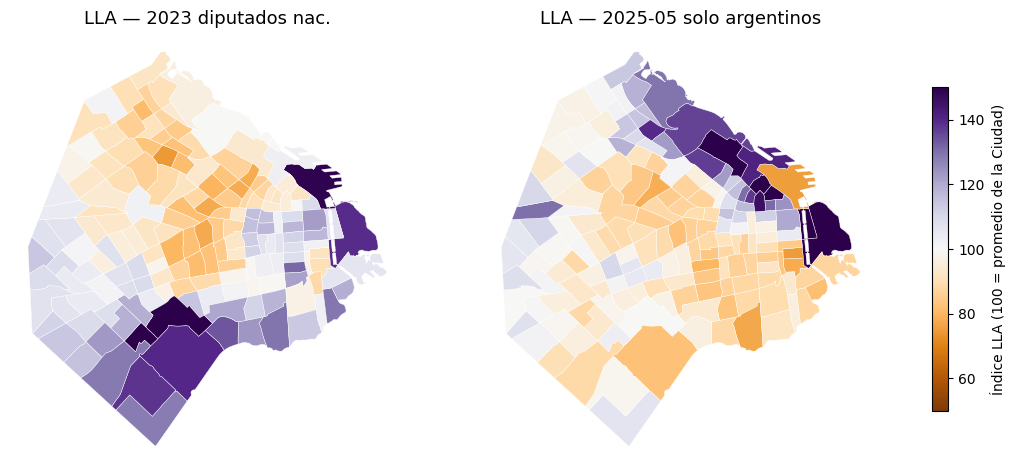

Donde LLA perdió más terreno relativo:
BARRIO
VILLA SOLDATI       -57.0
VILLA LUGANO        -40.0
NUEVA POMPEYA       -33.0
PARQUE AVELLANEDA   -33.0
BOCA                -33.0
CONSTITUCION        -27.0
VILLA RIACHUELO     -22.0
PARQUE PATRICIOS    -20.0
Name: cambio, dtype: float64

Donde LLA ganó más terreno relativo:
BARRIO
RETIRO           10.0
COGHLAN          10.0
COLEGIALES       15.0
NUÑEZ            21.0
PALERMO          28.0
BELGRANO         32.0
RECOLETA         34.0
PUERTO MADERO    45.0
Name: cambio, dtype: float64


In [38]:
import matplotlib.pyplot as plt

todo = pd.read_parquet(f'{DATA_PROCESSED}/positivos_circuito_todas.parquet')
todo['pct'] = todo['votos'] / todo.groupby(['eleccion', 'circuito_id'])['votos'].transform('sum') * 100

# Índice de LLA: % en el circuito / % en la Ciudad × 100
lla = todo[todo['espacio'] == 'LLA'].pivot_table(index='circuito_id', columns='eleccion',
                                                  values='pct', aggfunc='sum')
ciudad = (todo[todo['espacio'] == 'LLA'].groupby('eleccion')['votos'].sum()
          / todo.groupby('eleccion')['votos'].sum() * 100)
indice = lla / ciudad * 100

series = ['2023 diputados nac.', '2025-05 solo argentinos']
m = circuitos.merge(indice[series], left_on='circuito_id', right_index=True)
m['cambio'] = m['2025-05 solo argentinos'] - m['2023 diputados nac.']

# Dos mapas lado a lado, con la misma escala
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, s in zip(axes, series):
    m.plot(column=s, cmap='PuOr', vmin=50, vmax=150, ax=ax, edgecolor='white', linewidth=0.3)
    ax.set_title(f'LLA — {s}', fontsize=13)
    ax.set_axis_off()
sm = plt.cm.ScalarMappable(cmap='PuOr', norm=plt.Normalize(50, 150))
fig.colorbar(sm, ax=axes, shrink=0.6, label='Índice LLA (100 = promedio de la Ciudad)')
plt.show()

# Barrios donde más cayó y más subió el rendimiento relativo de LLA
por_barrio = m.groupby('BARRIO')['cambio'].mean().sort_values().round(0)
print('Donde LLA perdió más terreno relativo:')
print(por_barrio.head(8))
print('\nDonde LLA ganó más terreno relativo:')
print(por_barrio.tail(8))

### 5.2. Distribución por barrios y zonas

Se agregan los votos por barrio y se contrastan zonas del norte y del sur para describir diferencias territoriales.

In [39]:
t = todo[todo['eleccion'].isin(['2023 diputados nac.', '2025-05 solo argentinos'])]
t = t.merge(circuitos[['circuito_id', 'BARRIO']], on='circuito_id')
t['pct_barrio'] = t['votos'] / t.groupby(['BARRIO', 'eleccion'])['votos'].transform('sum') * 100

tabla = (t[t['espacio'].isin(['LLA', 'PRO'])]
         .pivot_table(index='BARRIO', columns=['espacio', 'eleccion'], values='pct_barrio', aggfunc='sum')
         .round(1))

sur = ['VILLA SOLDATI', 'VILLA LUGANO', 'NUEVA POMPEYA', 'PARQUE AVELLANEDA', 'BOCA']
norte = ['PUERTO MADERO', 'RECOLETA', 'BELGRANO', 'PALERMO', 'NUÑEZ']
print('SUR')
display(tabla.loc[sur])
print('NORTE')
display(tabla.loc[norte])

SUR


espacio                           LLA                          \
eleccion          2023 diputados nac. 2025-05 solo argentinos   
BARRIO                                                          
VILLA SOLDATI                    28.6                    25.0   
VILLA LUGANO                     27.3                    28.4   
NUEVA POMPEYA                    25.5                    28.2   
PARQUE AVELLANEDA                26.1                    28.9   
BOCA                             24.0                    25.9   

espacio                           PRO                          
eleccion          2023 diputados nac. 2025-05 solo argentinos  
BARRIO                                                         
VILLA SOLDATI                    19.5                     9.8  
VILLA LUGANO                     26.1                    10.9  
NUEVA POMPEYA                    30.2                    11.7  
PARQUE AVELLANEDA                29.5                    12.0  
BOCA                             29.3                    12.7

NORTE


espacio                       LLA                                         PRO  \
eleccion      2023 diputados nac. 2025-05 solo argentinos 2023 diputados nac.   
BARRIO                                                                          
PUERTO MADERO                25.4                    50.8                59.4   
RECOLETA                     18.8                    37.7                59.3   
BELGRANO                     18.1                    36.6                59.0   
PALERMO                      17.8                    34.8                55.4   
NUÑEZ                        17.8                    32.7                52.4   

espacio                                
eleccion      2025-05 solo argentinos  
BARRIO                                 
PUERTO MADERO                    22.2  
RECOLETA                         23.2  
BELGRANO                         23.7  
PALERMO                          21.3  
NUÑEZ                            20.2

In [40]:
t['zona'] = np.select([t['BARRIO'].isin(sur), t['BARRIO'].isin(norte)], ['Sur', 'Norte'], 'Resto')

z = t.groupby(['zona', 'eleccion', 'espacio'])['votos'].sum()
z = z / z.groupby(level=['zona', 'eleccion']).transform('sum') * 100
z.unstack(['zona', 'eleccion']).round(1)[['Sur', 'Norte']]

zona                                Sur                          \
eleccion            2023 diputados nac. 2025-05 solo argentinos   
espacio                                                           
Coalición Cívica                    NaN                     1.3   
Izquierda                           5.2                     3.9   
LLA                                26.4                    27.6   
Larreta                             NaN                     8.7   
Otras derechas                      NaN                     6.2   
Otros                               NaN                     0.4   
PRO                                27.0                    11.4   
Peronismo                          41.3                    33.9   
Peronismo disidente                 NaN                     3.9   
UCR / Lousteau                      NaN                     2.7   

zona                              Norte                          
eleccion            2023 diputados nac. 2025-05 solo argentinos  
espacio                                                          
Coalición Cívica                    NaN                     3.5  
Izquierda                           3.9                     2.7  
LLA                                18.2                    36.0  
Larreta                             NaN                     7.8  
Otras derechas                      NaN                     4.6  
Otros                               NaN                     0.2  
PRO                                57.0                    22.3  
Peronismo                          20.9                    19.1  
Peronismo disidente                 NaN                     1.5  
UCR / Lousteau                      NaN                     2.4

### 5.3. Participación, bastión y voto en disputa

Se estima la base electoral de la alianza en octubre, el techo de derecha observado en mayo y los componentes potenciales de persuasión y movilización.

,padron,base_oct,brecha,participacion,votos_persuasion,votos_abstencion
barrio,,,,,,
PALERMO,205189,56.0,12.4,67.6,17036.0,66566
CABALLITO,158467,45.5,12.9,73.1,14996.0,42714
RECOLETA,135518,61.4,12.2,66.7,11034.0,45086
BELGRANO,120745,60.0,12.4,69.7,10446.0,36697
FLORES,123622,46.8,12.3,69.2,10422.0,40052
ALMAGRO,110271,41.9,12.9,67.6,9543.0,36447
VILLA LUGANO,97425,40.0,14.4,65.0,9111.0,34081
VILLA URQUIZA,88888,48.7,14.0,73.0,9056.0,24036
BALVANERA,111716,44.7,12.4,63.8,8902.0,40459


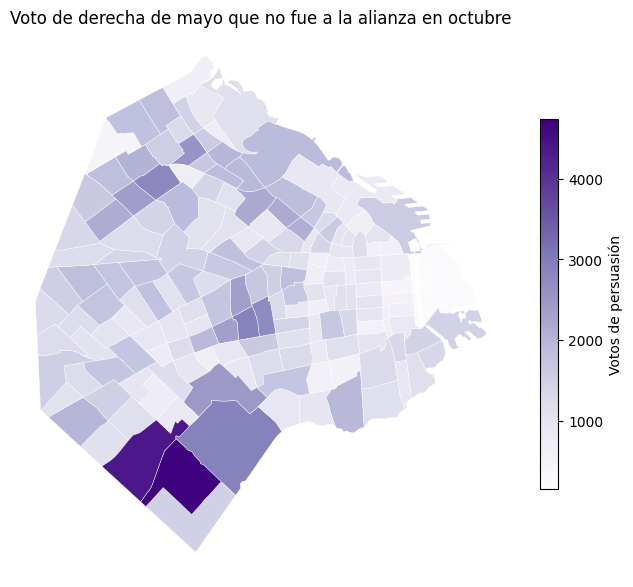

In [41]:
# Participación de octubre por circuito (votantes / padrón)
d25 = r25[r25['cargo_nombre'].str.contains('DIPUTADO')]
votantes = d25.groupby('circuito_id')['votos_cantidad'].sum()
padron = r25.drop_duplicates(['seccion_id', 'mesa_id']).groupby('circuito_id')['mesa_electores'].sum()

esp = todo.pivot_table(index='circuito_id', columns=['eleccion', 'espacio'],
                       values='pct', aggfunc='sum', fill_value=0)
may, octu = esp['2025-05 solo argentinos'], esp['2025-10 diputados nac.']

obj = pd.DataFrame({
    'barrio': circuitos.set_index('circuito_id')['BARRIO'],
    'padron': padron,
    'participacion': votantes / padron * 100,
    'base_oct': octu['LLA'],                                                        # bastión
    'techo_mayo': may['LLA'] + may['PRO'] + may['Larreta'] + may['Otras derechas'],
})
obj['brecha'] = obj['techo_mayo'] - obj['base_oct']                                 # persuasión
obj['votos_persuasion'] = (obj['brecha'].clip(lower=0) / 100 * votantes).round(0)
obj['votos_abstencion'] = padron - votantes                                         # movilización
obj.to_csv(f'{DATA_PROCESSED}/voto_en_disputa_por_circuito.csv')

# Resumen por barrio, ordenado por votos de persuasión
por_barrio = (obj.groupby('barrio')
                 .agg(padron=('padron', 'sum'), base_oct=('base_oct', 'mean'),
                      brecha=('brecha', 'mean'), participacion=('participacion', 'mean'),
                      votos_persuasion=('votos_persuasion', 'sum'),
                      votos_abstencion=('votos_abstencion', 'sum'))
                 .sort_values('votos_persuasion', ascending=False).round(1))
display(por_barrio.head(15))

# Mapa de votos de persuasión
ax = circuitos.merge(obj, left_on='circuito_id', right_index=True).plot(
    column='votos_persuasion', cmap='Purples', legend=True, figsize=(8, 8),
    edgecolor='white', linewidth=0.3, legend_kwds={'label': 'Votos de persuasión', 'shrink': 0.6})
ax.set_axis_off()
ax.set_title('Voto de derecha de mayo que no fue a la alianza en octubre');

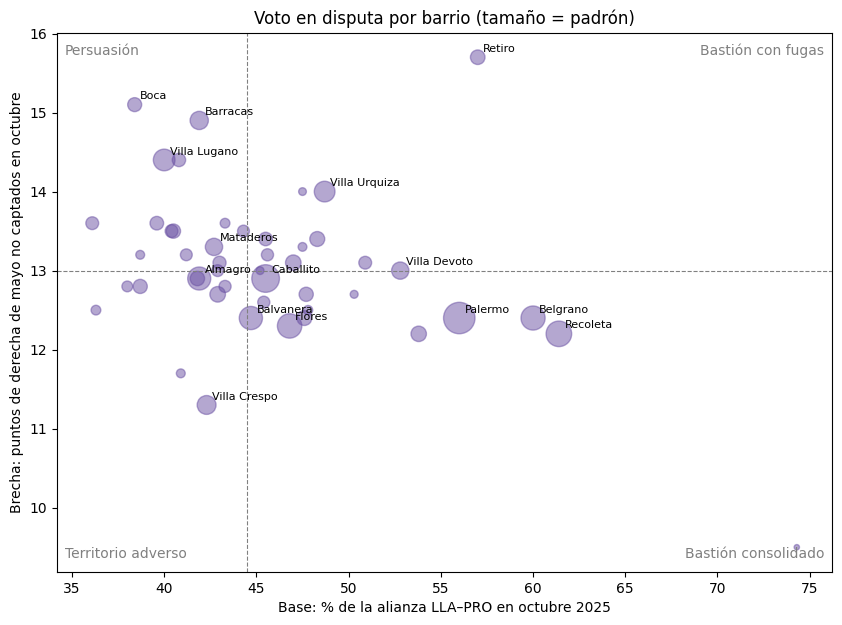

In [42]:
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(por_barrio['base_oct'], por_barrio['brecha'],
           s=por_barrio['padron'] / 400, alpha=0.5, color='#6a51a3')

for barrio, r in por_barrio.iterrows():
    if r['padron'] > 60000 or r['brecha'] > 14.5:      # etiquetar solo los grandes o destacados
        ax.annotate(barrio.title(), (r['base_oct'], r['brecha']), fontsize=8,
                    xytext=(4, 4), textcoords='offset points')

x0, y0 = por_barrio['base_oct'].median(), por_barrio['brecha'].median()
ax.axvline(x0, color='gray', ls='--', lw=0.8)
ax.axhline(y0, color='gray', ls='--', lw=0.8)

ax.text(0.99, 0.98, 'Bastión con fugas', transform=ax.transAxes, ha='right', va='top', color='gray')
ax.text(0.99, 0.02, 'Bastión consolidado', transform=ax.transAxes, ha='right', va='bottom', color='gray')
ax.text(0.01, 0.98, 'Persuasión', transform=ax.transAxes, ha='left', va='top', color='gray')
ax.text(0.01, 0.02, 'Territorio adverso', transform=ax.transAxes, ha='left', va='bottom', color='gray')

ax.set_xlabel('Base: % de la alianza LLA–PRO en octubre 2025')
ax.set_ylabel('Brecha: puntos de derecha de mayo no captados en octubre')
ax.set_title('Voto en disputa por barrio (tamaño = padrón)')
plt.show()

In [43]:
obj['zona'] = obj['barrio']
obj.loc['00005', 'zona'] = 'RETIRO (B. MUGICA)'
obj.loc[(obj['barrio'] == 'RETIRO') & (obj.index != '00005'), 'zona'] = 'RETIRO (RESTO)'

por_barrio = (obj.groupby('zona')
                 .agg(padron=('padron', 'sum'), base_oct=('base_oct', 'mean'),
                      brecha=('brecha', 'mean'), participacion=('participacion', 'mean'),
                      votos_persuasion=('votos_persuasion', 'sum'),
                      votos_abstencion=('votos_abstencion', 'sum'))
                 .round(1))

display(por_barrio.loc[['RETIRO (B. MUGICA)', 'RETIRO (RESTO)']])
display(por_barrio.sort_values('base_oct', ascending=False).head(3))   # ¿quién es el de ~75%?

,padron,base_oct,brecha,participacion,votos_persuasion,votos_abstencion
zona,,,,,,
RETIRO (B. MUGICA),13252,33.8,26.8,45.1,1600.0,7280
RETIRO (RESTO),30791,64.7,11.9,63.2,2274.0,11188


,padron,base_oct,brecha,participacion,votos_persuasion,votos_abstencion
zona,,,,,,
PUERTO MADERO,5925,74.3,9.5,65.6,371.0,2034
RETIRO (RESTO),30791,64.7,11.9,63.2,2274.0,11188
RECOLETA,135518,61.4,12.2,66.7,11034.0,45086


### 5.4. Nivel socioeconómico, quintiles y regresiones WLS

Se relacionan los indicadores censales con el voto a LLA y se estiman modelos ponderados por población. Los coeficientes se estandarizan para facilitar su comparación.

Correlación población censo – padrón electoral: 0.944


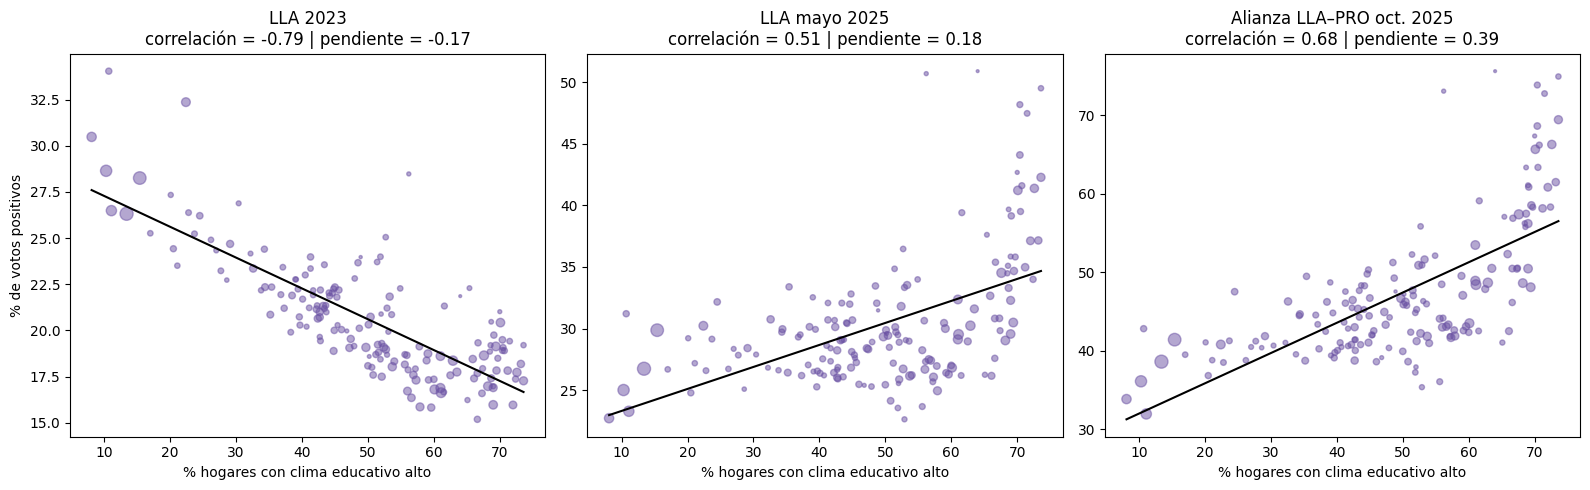

,2023 diputados nac.,2025-05 solo argentinos,2025-10 diputados nac.
clima_alto,-0.79,0.51,0.68
universitario,-0.72,0.59,0.75
sin_cobertura,0.84,-0.38,-0.54
nbi,0.58,-0.37,-0.48
jovenes,0.58,-0.01,-0.10
migrantes,0.71,-0.15,-0.28
alquila,-0.01,-0.10,-0.08


In [44]:
import numpy as np
import matplotlib.pyplot as plt

# Datos electorales (por si la sesión es nueva)
todo = pd.read_parquet(f'{DATA_PROCESSED}/positivos_circuito_todas.parquet')
todo['circuito_id'] = todo['circuito_id'].astype(str).str.zfill(5)
todo['pct'] = todo['votos'] / todo.groupby(['eleccion', 'circuito_id'])['votos'].transform('sum') * 100
lla = todo[todo['espacio'] == 'LLA'].pivot_table(index='circuito_id', columns='eleccion',
                                                  values='pct', aggfunc='sum')

# 1. Control: población del censo contra padrón electoral de octubre, por circuito
r25 = pd.read_parquet(f'{DATA_PROCESSED}/caba_2025_octubre.parquet',
                      columns=['seccion_id', 'mesa_id', 'circuito_id', 'mesa_electores'])
r25['circuito_id'] = r25['circuito_id'].astype(str).str.zfill(5)
padron = r25.drop_duplicates(['seccion_id', 'mesa_id']).groupby('circuito_id')['mesa_electores'].sum()
print('Correlación población censo – padrón electoral:', round(ind['poblacion'].corr(padron), 3))

# 2. Base de análisis: indicadores del censo + voto a LLA
base = ind.join(lla)
base.to_csv(f'{DATA_PROCESSED}/base_analisis_circuito.csv')

series = {'2023 diputados nac.': 'LLA 2023', '2025-05 solo argentinos': 'LLA mayo 2025',
          '2025-10 diputados nac.': 'Alianza LLA–PRO oct. 2025'}

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True)
for ax, (col, titulo) in zip(axes, series.items()):
    x, y = base['clima_alto'], base[col]
    pendiente, ordenada = np.polyfit(x, y, 1)
    ax.scatter(x, y, s=base['poblacion'] / 800, alpha=0.5, color='#6a51a3')
    xs = np.linspace(x.min(), x.max(), 50)
    ax.plot(xs, ordenada + pendiente * xs, color='black', lw=1.5)
    ax.set_title(f'{titulo}\ncorrelación = {x.corr(y):.2f} | pendiente = {pendiente:.2f}')
    ax.set_xlabel('% hogares con clima educativo alto')
axes[0].set_ylabel('% de votos positivos')
plt.tight_layout()
plt.show()

# 3. Correlación de cada indicador con el voto a LLA, en cada elección
display(base[list(ind.columns.drop('poblacion'))].corrwith(base[list(series)]) if False else
        base[list(ind.columns.drop('poblacion')) + list(series)].corr()
        .loc[ind.columns.drop('poblacion'), list(series)].round(2))

/tmp/ipykernel_496/3901484958.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  quint = pd.DataFrame({nombre: base.groupby('quintil', observed=True).apply(ponderado, col)
/tmp/ipykernel_496/3901484958.py:8: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  quint = pd.DataFrame({nombre: base.groupby('quintil', observed=True).apply(ponderado, col)
/tmp/ipykernel_496/3901484958.py:8: DeprecationWarning: DataFram

,LLA 2023,LLA mayo 2025,Alianza LLA–PRO oct. 2025
quintil,,,
Q1\n(más bajo),25.8,27.7,40.3
Q2,21.4,28.5,43.6
Q3,20.0,28.9,45.1
Q4,17.9,28.9,46.2
Q5\n(más alto),18.1,35.8,58.2


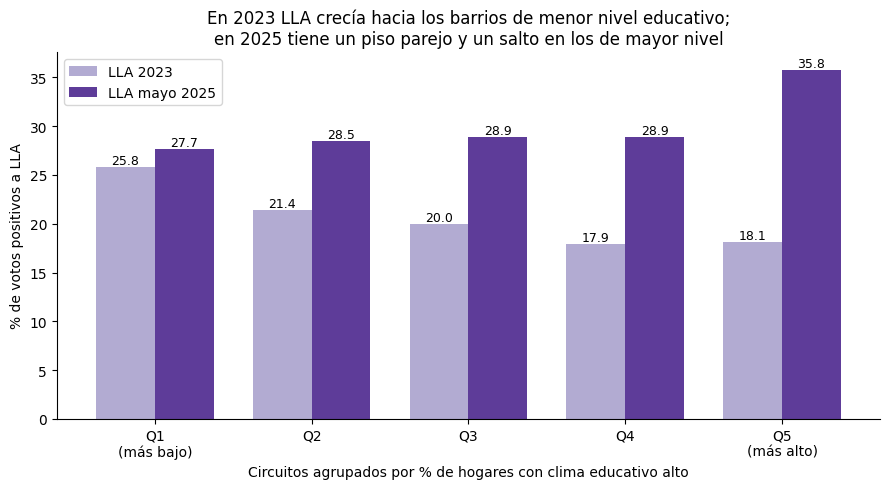

In [45]:
base['quintil'] = pd.qcut(base['clima_alto'], 5,
                          labels=['Q1\n(más bajo)', 'Q2', 'Q3', 'Q4', 'Q5\n(más alto)'])

# Promedio ponderado por población de cada quintil
def ponderado(g, col):
    return np.average(g[col], weights=g['poblacion'])

quint = pd.DataFrame({nombre: base.groupby('quintil', observed=True).apply(ponderado, col)
                      for col, nombre in series.items()}).round(1)
quint.to_csv(f'{DATA_PROCESSED}/lla_por_quintil_educativo.csv')
display(quint)

ax = quint[['LLA 2023', 'LLA mayo 2025']].plot(kind='bar', figsize=(9, 5), rot=0,
                                               color=['#b2abd2', '#5e3c99'], width=0.75)
for c in ax.containers:
    ax.bar_label(c, fmt='%.1f', fontsize=9)
ax.set_xlabel('Circuitos agrupados por % de hogares con clima educativo alto')
ax.set_ylabel('% de votos positivos a LLA')
ax.set_title('En 2023 LLA crecía hacia los barrios de menor nivel educativo;\nen 2025 tiene un piso parejo y un salto en los de mayor nivel')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

In [46]:
import statsmodels.formula.api as smf

# Estandarizamos: cada variable en "desvíos estándar", así los coeficientes se comparan entre sí
z = base[['clima_alto', 'jovenes', 'migrantes']].apply(lambda s: (s - s.mean()) / s.std())

res = {}
for col, nombre in series.items():
    d = z.assign(voto=(base[col] - base[col].mean()) / base[col].std())
    modelo = smf.wls('voto ~ clima_alto + jovenes + migrantes', data=d, weights=base['poblacion']).fit()
    res[nombre] = modelo.params.drop('Intercept').round(2).astype(str) + \
                  modelo.pvalues.drop('Intercept').map(lambda p: ' *' if p < 0.05 else '')
    res[nombre]['R²'] = f'{modelo.rsquared:.2f}'
pd.DataFrame(res)

,LLA 2023,LLA mayo 2025,Alianza LLA–PRO oct. 2025
clima_alto,-0.66 *,0.47 *,0.64 *
jovenes,0.24 *,0.31 *,0.27 *
migrantes,0.09,-0.16,-0.14
R²,0.81,0.32,0.54


### 5.5. Control de robustez: legisladores porteños 2023

La elección local de 2023 se incorpora como contraste adicional, no como parte de la comparación electoral principal.

In [47]:
import statsmodels.formula.api as smf

# 1. LLA en legisladores porteños 2023, solo mesas de argentinos
r23 = pd.read_parquet(f'{DATA_PROCESSED}/caba_2023_generales.parquet',
                      columns=['circuito_id', 'mesa_tipo', 'cargo_nombre', 'votos_tipo',
                               'agrupacion_nombre', 'votos_cantidad'])
r23['circuito_id'] = r23['circuito_id'].astype(str).str.zfill(5)
leg = r23[r23['cargo_nombre'].str.contains('CIUDAD AUTONOMA') &
          (r23['mesa_tipo'] == 'NATIVOS') & (r23['votos_tipo'] == 'POSITIVO')]
pos = leg.groupby('circuito_id')['votos_cantidad'].sum()
lla_leg = (leg[leg['agrupacion_nombre'].str.contains('LIBERTAD AVANZA')]
           .groupby('circuito_id')['votos_cantidad'].sum())
base['LLA leg. 2023'] = (lla_leg / pos * 100).reindex(base.index)
print(f"LLA legisladores 2023 (solo argentinos), Ciudad: {lla_leg.sum() / pos.sum():.1%}")

# 2. Quintiles con las dos bases de 2023
comp_series = {'2023 diputados nac.': 'LLA dip. 2023', 'LLA leg. 2023': 'LLA leg. 2023',
               '2025-05 solo argentinos': 'LLA mayo 2025'}
rob = pd.DataFrame({n: base.groupby('quintil', observed=True)
                           .apply(lambda g, c=c: np.average(g[c], weights=g['poblacion']))
                    for c, n in comp_series.items()}).round(1)
rob['cambio dip.'] = rob['LLA mayo 2025'] - rob['LLA dip. 2023']
rob['cambio leg.'] = rob['LLA mayo 2025'] - rob['LLA leg. 2023']
display(rob)

# 3. Regresión con la nueva base
z = base[['clima_alto', 'jovenes', 'migrantes']].apply(lambda s: (s - s.mean()) / s.std())
d = z.assign(voto=(base['LLA leg. 2023'] - base['LLA leg. 2023'].mean()) / base['LLA leg. 2023'].std())
m = smf.wls('voto ~ clima_alto + jovenes + migrantes', data=d, weights=base['poblacion']).fit()
print(m.params.drop('Intercept').round(2), '\nR²:', round(m.rsquared, 2))

LLA legisladores 2023 (solo argentinos), Ciudad: 13.3%


/tmp/ipykernel_496/1355838183.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g, c=c: np.average(g[c], weights=g['poblacion']))
/tmp/ipykernel_496/1355838183.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g, c=c: np.average(g[c], weights=g['poblacion']))
/tmp/ipykernel_496/1355838183.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. Th

,LLA dip. 2023,LLA leg. 2023,LLA mayo 2025,cambio dip.,cambio leg.
quintil,,,,,
Q1\n(más bajo),25.8,18.3,27.7,1.9,9.4
Q2,21.4,14.0,28.5,7.1,14.5
Q3,20.0,12.7,28.9,8.9,16.2
Q4,17.9,11.5,28.9,11.0,17.4
Q5\n(más alto),18.1,11.3,35.8,17.7,24.5


clima_alto   -0.59
jovenes       0.21
migrantes     0.22
dtype: float64 
R²: 0.85


### 5.6. Participación electoral

Se calculan las tasas por circuito y quintil, y se modelan sus diferencias entre elecciones.

### Estimación de participación de mayo 2025

La participación de mayo es una estimación, no un conteo directo de votantes argentinos: **votantes argentinos estimados = votantes totales × (votos positivos argentinos / votos positivos totales)**. El denominador de participación es el padrón de octubre de 2025. Se mantiene esta fórmula sin modificaciones.

In [48]:
# Recuperar las bases DINE completas: las celdas de robustez anteriores usan subconjuntos de columnas.
r23 = pd.read_parquet(f'{DATA_PROCESSED}/caba_2023_generales.parquet')
r25 = pd.read_parquet(f'{DATA_PROCESSED}/caba_2025_octubre.parquet')
for df in (r23, r25):
    df['circuito_id'] = df['circuito_id'].astype(str).str.zfill(5)

In [49]:
# Padrón y votantes de la DINE (solo mesas de argentinos)
def participacion_dine(df, filtro_cargo):
    nat = df[df['mesa_tipo'] == 'NATIVOS']
    padron = nat.drop_duplicates(['seccion_id', 'mesa_id']).groupby('circuito_id')['mesa_electores'].sum()
    votantes = nat[nat['cargo_nombre'].str.contains(filtro_cargo)].groupby('circuito_id')['votos_cantidad'].sum()
    return padron, votantes

padron23, vot23 = participacion_dine(r23, 'DIPUTADO NACIONAL')
padron25, vot25 = participacion_dine(r25, 'DIPUTADO')

# Mayo: votantes argentinos estimados
tot_mayo = mayo_circ[mayo_circ['agrupacion'] == 'VOTOS TOTALES'].groupby('circuito_id')['votos'].sum()
pos_todos = mayo_circ[mayo_circ['agrupacion_id'].notna()].groupby('circuito_id')['votos'].sum()
pos_arg = mayo_arg.groupby('circuito_id')['votos'].sum()
vot_mayo = tot_mayo * (pos_arg / pos_todos)

part = pd.DataFrame({
    'Participación 2023 (%)':     vot23 / padron23 * 100,
    'Participación mayo 2025 (%)': vot_mayo / padron25 * 100,
    'Participación oct. 2025 (%)': vot25 / padron25 * 100,
    'padron': padron25,
}).round(1)
part.to_csv(f'{DATA_PROCESSED}/participacion_por_circuito.csv')

# Controles: totales de la Ciudad
print(f"2023:     {vot23.sum() / padron23.sum():.1%}")
print(f"Mayo 2025: {vot_mayo.sum() / padron25.sum():.1%}   (oficial, solo argentinos: 62,3%)")
print(f"Oct. 2025: {vot25.sum() / padron25.sum():.1%}")
display(part.describe().round(1))

2023:     75.4%
Mayo 2025: 62.3%   (oficial, solo argentinos: 62,3%)
Oct. 2025: 68.8%


,Participación 2023 (%),Participación mayo 2025 (%),Participación oct. 2025 (%),padron
count,167.0,167.0,167.0,167.0
mean,75.1,62.0,68.6,15080.1
std,4.1,5.7,4.8,6671.0
min,62.3,40.8,45.1,2581.0
25%,72.9,59.2,66.0,11076.5
50%,75.4,62.9,69.4,13323.0
75%,78.4,66.8,72.2,18045.0
max,81.6,69.4,75.4,48828.0


In [50]:
base = ind.join(part)
base['caida_mayo'] = base['Participación mayo 2025 (%)'] - base['Participación 2023 (%)']
base['recupero_oct'] = base['Participación oct. 2025 (%)'] - base['Participación mayo 2025 (%)']

# 1. Participación por quintil de nivel educativo (ponderado por padrón)
base['quintil'] = pd.qcut(base['clima_alto'], 5, labels=['Q1 (más bajo)', 'Q2', 'Q3', 'Q4', 'Q5 (más alto)'])
cols_p = ['Participación 2023 (%)', 'Participación mayo 2025 (%)', 'Participación oct. 2025 (%)',
          'caida_mayo', 'recupero_oct']
quint_p = (base.groupby('quintil', observed=True)[cols_p + ['padron']]
               .apply(lambda g: pd.Series({c: np.average(g[c], weights=g['padron']) for c in cols_p}))
               .round(1))
quint_p.to_csv(f'{DATA_PROCESSED}/participacion_por_quintil.csv')
display(quint_p)

# 2. Regresión: qué explica la participación y su caída
z = base[['clima_alto', 'jovenes', 'migrantes']].apply(lambda s: (s - s.mean()) / s.std())
res = {}
for col in ['Participación 2023 (%)', 'Participación mayo 2025 (%)', 'caida_mayo', 'recupero_oct']:
    d = z.assign(y=(base[col] - base[col].mean()) / base[col].std())
    m = smf.wls('y ~ clima_alto + jovenes + migrantes', data=d, weights=base['padron']).fit()
    r = m.params.drop('Intercept').round(2).astype(str) + \
        m.pvalues.drop('Intercept').map(lambda p: ' *' if p < 0.05 else '')
    r['R²'] = f'{m.rsquared:.2f}'
    res[col] = r
display(pd.DataFrame(res))

# 3. Chequeo: ¿la alianza sumó más donde más se recuperó la participación?
alianza = pd.read_csv(f'{DATA_PROCESSED}/alianza_por_circuito.csv', dtype={'circuito_id': str}).set_index('circuito_id')
base = base.join(alianza[['diferencia_arg']])
print('Correlación recupero de participación – diferencia de la alianza:',
      round(base['recupero_oct'].corr(base['diferencia_arg']), 2))
print('Sin el Barrio Mugica:',
      round(base.drop('00005')['recupero_oct'].corr(base.drop('00005')['diferencia_arg']), 2))

# Los 5 circuitos con menor participación en mayo
display(base.nsmallest(5, 'Participación mayo 2025 (%)')
        .join(circuitos.set_index('circuito_id')['BARRIO'])
        [['BARRIO', 'Participación 2023 (%)', 'Participación mayo 2025 (%)', 'Participación oct. 2025 (%)']])

,Participación 2023 (%),Participación mayo 2025 (%),Participación oct. 2025 (%),caida_mayo,recupero_oct
quintil,,,,,
Q1 (más bajo),73.8,57.8,65.5,-16.0,7.8
Q2,76.7,64.2,70.5,-12.5,6.3
Q3,75.9,63.3,69.5,-12.6,6.2
Q4,77.0,65.4,70.6,-11.6,5.3
Q5 (más alto),74.0,61.4,68.2,-12.6,6.8


,Participación 2023 (%),Participación mayo 2025 (%),caida_mayo,recupero_oct
clima_alto,-0.41 *,-0.23 *,0.12,-0.07
jovenes,-0.37 *,-0.35 *,-0.16,0.28 *
migrantes,-0.54 *,-0.62 *,-0.43 *,0.08
R²,0.64,0.77,0.46,0.19


Correlación recupero de participación – diferencia de la alianza: 0.05
Sin el Barrio Mugica: 0.0


,BARRIO,Participación 2023 (%),Participación mayo 2025 (%),Participación oct. 2025 (%)
circuito_id,,,,
00005,RETIRO,62.3,40.8,45.1
00016,CONSTITUCION,67.6,45.1,62.6
00047,BARRACAS,67.5,45.3,57.1
00019,CONSTITUCION,69.1,48.2,57.3
00014,MONTSERRAT,63.7,48.4,55.5


In [51]:
# Persistencia de resultados analíticos intermedios.
base.to_csv(f'{DATA_PROCESSED}/base_analisis_circuito.csv')
part.to_csv(f'{DATA_PROCESSED}/participacion_por_circuito.csv')
quint_p.to_csv(f'{DATA_PROCESSED}/participacion_por_quintil.csv')
obj.to_csv(f'{DATA_PROCESSED}/voto_en_disputa_por_circuito.csv')

### Persistencia de la sección 5

Se guardan las bases por circuito, participación, quintiles y voto en disputa que alimentan las exportaciones.

## 6. Datos para gráficos (CSV para Datawrapper)

Se generan los archivos de visualización conservando los nombres de salida originales. Los productos finales se escriben en `output/datawrapper/`.

In [52]:
import os, json

OUT = f'{OUTPUT}/datawrapper'
os.makedirs(OUT, exist_ok=True)

# 1. Gráfico de barras por quintil
q = rob[['LLA dip. 2023', 'LLA mayo 2025']].copy()
q.index = ['Q1 (más bajo)', 'Q2', 'Q3', 'Q4', 'Q5 (más alto)']
q.index.name = 'Quintil de nivel educativo'
q.to_csv(f'{OUT}/1_quintiles.csv')

# 2. Mapa: índice LLA 2023 y 2025 por circuito, con barrio y comuna
# Reconstruimos la base electoral para evitar depender de `base`,
# que fue sobrescrita en la sección de participación.
base_mapa = ind.join(lla)

lla_c = base_mapa[['2023 diputados nac.', '2025-05 solo argentinos']]
ciudad = {
    c: np.average(base_mapa[c], weights=base_mapa['poblacion'])
    for c in lla_c.columns
}

mapa = pd.DataFrame({
    'circuito': circuitos.set_index('circuito_id')['ID'].astype(str),
    'barrio': circuitos.set_index('circuito_id')['BARRIO'].str.title(),
    'comuna': circuitos.set_index('circuito_id')['COMUNA'],
    'LLA 2023 (%)': lla_c['2023 diputados nac.'].round(1),
    'LLA mayo 2025 (%)': lla_c['2025-05 solo argentinos'].round(1),
    'Índice 2023': (
        lla_c['2023 diputados nac.'] /
        ciudad['2023 diputados nac.'] * 100
    ).round(0),
    'Índice 2025': (
        lla_c['2025-05 solo argentinos'] /
        ciudad['2025-05 solo argentinos'] * 100
    ).round(0),
    'Clima educativo alto (%)': base_mapa['clima_alto'],
})
mapa.to_csv(f'{OUT}/2_mapa_indice_lla.csv', index=False)

# 3. Mapa base de circuitos para Datawrapper
geo = circuitos[['ID', 'BARRIO', 'geometry']].copy()
geo['ID'] = geo['ID'].astype(str)
geo['geometry'] = geo['geometry'].simplify(0.0001)
geo.to_file(f'{OUT}/circuitos_caba.geojson', driver='GeoJSON')

# 4. Cuadrantes de voto en disputa por barrio
vd = pd.read_csv(
    f'{DATA_PROCESSED}/voto_en_disputa_por_circuito.csv',
    dtype={'circuito_id': str}
)
print('Columnas de voto en disputa:', vd.columns.tolist())

print('Archivos en', OUT, ':', os.listdir(OUT))

Columnas de voto en disputa: ['circuito_id', 'barrio', 'padron', 'participacion', 'base_oct', 'techo_mayo', 'brecha', 'votos_persuasion', 'votos_abstencion', 'zona']
Archivos en output/datawrapper : ['1_quintiles.csv', '2_mapa_indice_lla.csv', '3_voto_en_disputa.csv', 'circuitos_caba.geojson']


In [53]:
vd = pd.read_csv(f'{DATA_PROCESSED}/voto_en_disputa_por_circuito.csv', dtype={'circuito_id': str})

# Separar el Barrio Mugica del resto de Retiro, como hicimos antes
vd['zona'] = vd['barrio']
vd.loc[vd['circuito_id'] == '00005', 'zona'] = 'RETIRO (B. MUGICA)'
vd.loc[(vd['barrio'] == 'RETIRO') & (vd['circuito_id'] != '00005'), 'zona'] = 'RETIRO (RESTO)'

cuad = (vd.groupby('zona')
          .apply(lambda g: pd.Series({
              'Padrón': g['padron'].sum(),
              'Base alianza oct. 2025 (%)': np.average(g['base_oct'], weights=g['padron']),
              'Brecha (puntos)': np.average(g['brecha'], weights=g['padron']),
          }), include_groups=False)
          .round(1).reset_index())
cuad['zona'] = cuad['zona'].str.title()
cuad = cuad.rename(columns={'zona': 'Barrio'})
cuad.to_csv(f'{OUT}/3_voto_en_disputa.csv', index=False)
cuad.sort_values('Padrón', ascending=False).head()

,Barrio,Padrón,Base alianza oct. 2025 (%),Brecha (puntos)
20,Palermo,205189.0,56.5,12.3
7,Caballito,158467.0,46.1,13.0
27,Recoleta,135518.0,60.9,12.2
12,Flores,123622.0,46.2,12.5
4,Belgrano,120745.0,60.6,12.4


### Persistencia de la sección 6

Los CSV y el GeoJSON para Datawrapper quedan en `output/datawrapper/`, sin alterar sus nombres originales.

## 7. Resumen de validaciones

Las validaciones se ejecutan al final para comprobar cobertura territorial, reconstrucción de mayo, estimación de participación y consistencia entre población censal y padrón. Cada control informa `OK` o `ERROR` y utiliza tolerancias explícitas.

In [54]:
# Completar con porcentajes publicados oficialmente.
# Estructura: (nombre_de_serie, espacio_politico): porcentaje_oficial.
# Ejemplo: ('2023 diputados nac.', 'LLA'): 29.5
OFICIALES = {}


def comparar_porcentajes_oficiales(oficiales, datos, tolerancia=0.15):
    """Compara porcentajes oficiales con los calculados sobre votos positivos.

    OFICIALES debe contener todas las combinaciones (eleccion, espacio) que se
    quieran validar. Si está vacío o incompleto, se omite el control completo.
    """
    if not oficiales:
        print('AVISO: OFICIALES está vacío; se saltea la comparación de porcentajes oficiales.')
        return None
    totales_por_serie = datos.groupby(['eleccion', 'espacio'])['votos'].sum()
    denominadores = totales_por_serie.groupby(level='eleccion').transform('sum')
    calculados = totales_por_serie / denominadores * 100
    claves_esperadas = set(calculados.index.tolist())
    claves_informadas = set(oficiales.keys())
    faltantes = sorted(claves_esperadas - claves_informadas)
    sobrantes = sorted(claves_informadas - claves_esperadas)
    if faltantes or sobrantes:
        print('AVISO: OFICIALES está incompleto o contiene claves no reconocidas; se saltea la comparación.')
        print('Claves faltantes:', faltantes)
        print('Claves no reconocidas:', sobrantes)
        return None
    diferencias = {clave: abs(float(calculados.loc[clave]) - float(valor))
                   for clave, valor in oficiales.items()}
    ok = all(dif <= tolerancia for dif in diferencias.values())
    print(('OK' if ok else 'ERROR') + ': porcentajes oficiales; diferencias en puntos porcentuales:',
          {str(k): round(v, 3) for k, v in diferencias.items()})
    return ok


def reportar_validacion(nombre, condicion, detalle=''):
    estado = 'OK' if bool(condicion) else 'ERROR'
    print(f'{estado}: {nombre}' + (f' — {detalle}' if detalle else ''))
    return bool(condicion)

resultados_validacion = []

# 1. 167 circuitos en cada serie electoral disponible.
series_esperadas = [
    '2023 diputados nac.',
    '2023 legisladores',  # control de robustez
    '2025-05 legisladores',
    '2025-05 solo argentinos',
    '2025-10 diputados nac.',
]
for serie in series_esperadas:
    n = todo.loc[todo['eleccion'] == serie, 'circuito_id'].nunique()
    resultados_validacion.append(reportar_validacion(
        f'167 circuitos — {serie}', n == 167, f'{n} circuitos encontrados'))

# 2. Diferencia entre total oficial por comuna y total reconstruido por escuelas.
# La diferencia esperada es de 870 votos de mesas sin ubicación territorial.
if val is not None:
    if 'TOTAL' in val.index:
        diferencia_no_ubicada = (val.loc['TOTAL', 'oficial_comuna'] -
                                 val.loc['TOTAL', 'suma_escuelas'])
    else:
        diferencia_no_ubicada = (val['oficial_comuna'].sum() - val['suma_escuelas'].sum())
    resultados_validacion.append(reportar_validacion(
        'Mayo 2025 — diferencia territorial de 870 votos',
        abs(float(diferencia_no_ubicada) - 870) < 0.5,
        f'diferencia oficial - reconstruido = {diferencia_no_ubicada:.0f} votos'))
else:
    pass  # La omisión ya se informó al cargar los totales oficiales.

# 3. Participación estimada de mayo (votantes argentinos estimados / padrón de octubre 2025).
participacion_mayo_ciudad = float(vot_mayo.sum() / padron25.sum() * 100)
resultados_validacion.append(reportar_validacion(
    'Participación estimada mayo 2025 ≈ 62,3%',
    abs(participacion_mayo_ciudad - 62.3) < 0.3,
    f'{participacion_mayo_ciudad:.2f}%'))

# 4. Correlación entre población censal y padrón electoral por circuito.
padron_correlacion = r25.drop_duplicates(['seccion_id', 'mesa_id']).groupby('circuito_id')['mesa_electores'].sum()
correlacion_censo_padron = ind['poblacion'].corr(padron_correlacion)
resultados_validacion.append(reportar_validacion(
    'Correlación población censal vs. padrón > 0,9',
    pd.notna(correlacion_censo_padron) and correlacion_censo_padron > 0.9,
    f'r = {correlacion_censo_padron:.3f}'))

# 5. Comparación opcional contra porcentajes oficiales publicados.
resultado_oficiales = comparar_porcentajes_oficiales(OFICIALES, todo)
if resultado_oficiales is not None:
    resultados_validacion.append(resultado_oficiales)

print('\nResumen:', sum(resultados_validacion), 'de', len(resultados_validacion),
      'validaciones estructurales aprobadas.')

OK: 167 circuitos — 2023 diputados nac. — 167 circuitos encontrados
OK: 167 circuitos — 2023 legisladores — 167 circuitos encontrados
OK: 167 circuitos — 2025-05 legisladores — 167 circuitos encontrados
OK: 167 circuitos — 2025-05 solo argentinos — 167 circuitos encontrados
OK: 167 circuitos — 2025-10 diputados nac. — 167 circuitos encontrados
OK: Participación estimada mayo 2025 ≈ 62,3% — 62.30%
OK: Correlación población censal vs. padrón > 0,9 — r = 0.944
AVISO: OFICIALES está vacío; se saltea la comparación de porcentajes oficiales.

Resumen: 7 de 7 validaciones estructurales aprobadas.


### Persistencia de la sección 7

Se guarda el resumen de validaciones para dejar trazabilidad de los controles ejecutados.

In [55]:
pd.DataFrame({
    'validacion': [f'validacion_{i+1}' for i in range(len(resultados_validacion))],
    'ok': resultados_validacion,
}).to_csv(f'{DATA_PROCESSED}/resumen_validaciones.csv', index=False)